# Figure 3 · Cortical-depth MD profiles and thickness-related confounding

This notebook follows the sequence **observe curves → summarize shape → assess thickness association → inspect what remains after adjustment**.

All panels use the registration-QC-passed cohort with the unified subject-level coverage criterion (≥95%), the original fsaverage analysis mask, exact DK labels, pial-to-white depth order, and whole-profile validity rule. Five prespecified registration failures are excluded. Missing values are not imputed.

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
%matplotlib inline
plt.close('all')
plt.rcdefaults()
plt.rcParams.update({'figure.dpi': 120., 'savefig.dpi': 120.})

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'analysis_results/figure3/computation/run_all_figure3.py').is_file())
submission = json.loads((REPO_ROOT / 'analysis_results/figure3/computation/submission_20261108.json').read_text())
OUTPUT = Path(os.environ.get('FIGURE3_OUTPUT_DIR', submission['output_dir']))
TABLES, QC, FIGURES = OUTPUT / 'tables', OUTPUT / 'qc', OUTPUT / 'figures'
if not (QC / 'complete.json').is_file():
    raise RuntimeError(f'Full analysis is not complete: {OUTPUT}')
preparation = json.loads((QC / 'preparation.json').read_text())
analysis = json.loads((QC / 'analysis.json').read_text())
subjects = pd.read_csv(TABLES / 'figure3_subjects.csv', dtype={'subject_id': str})
N = len(subjects)
assert preparation['n_subjects'] == analysis['n_subjects'] == N == 313
assert subjects.subject_id.is_unique
assert preparation['depth_direction'] == 'pial_to_white'
assert analysis['mean_centered_row_mean_max_abs'] < analysis['mean_centering_tolerance']
print(f'Results: {OUTPUT}\nFinal cohort: N = {N}')

Results: /mnt/newStor/paros/paros_WORK/xintong/results/figure3_depth_thickness_coverage95
Final cohort: N = 313


## Cohort, coverage, and missing-region QC

A profile is invalid as a whole if any depth is NaN, Inf, nonpositive, or invalid under the existing Option 3 QC mask. Missing depths are never interpolated. After the fixed registration-QC exclusions, inclusion requires bilateral `sum(in_analysis_mask & column_valid) / sum(in_analysis_mask) ≥ 0.95`. Bootstrap intervals resample subjects, not vertices.

In [2]:
excluded = pd.read_csv(REPO_ROOT / 'manifests/figure4_registration_qc_exclusions.csv', dtype={'subject_id': str})
assert set(excluded.subject_id).isdisjoint(subjects.subject_id)
assert set(preparation['known_qc_exclusions']) == set(excluded.subject_id)
missing = pd.read_csv(QC / 'missing_subject_region_cells.csv')
coverage = pd.read_csv(TABLES / 'figure3_coverage_by_vertex.csv')
mask = np.load(TABLES / 'figure3_analysis_mask.npy')
assert len(missing) == analysis['n_missing_subject_region_cells'] == 0
assert mask.shape[0] == 2 and mask.sum() == preparation['n_analysis_vertices']
input_qc = pd.read_csv(QC / 'subject_input_qc.csv', dtype={'subject_id': str})
assert input_qc.actual_pial_white_endpoint_check.all()
assert input_qc.max_weight_sum_error.max() < 1e-6
assert set(input_qc.subject_id) == set(subjects.subject_id)
display(pd.DataFrame({
    'check': ['Final subjects', 'Registration-QC exclusions', 'Analysis-mask vertices',
              'Valid profiles used for PCA', 'Missing subject–region cells'],
    'value': [N, len(excluded), int(mask.sum()),
              analysis['n_valid_profiles_used_for_pca'], len(missing)]
}))
display(subjects[['valid_vertices', 'atlas_coverage_fraction']].describe())

,check,value
0,Final subjects,313
1,Registration-QC exclusions,5
2,Analysis-mask vertices,299879
3,Valid profiles used for PCA,92759011
4,Missing subject–region cells,0


,valid_vertices,atlas_coverage_fraction
count,313.000000,313.000000
mean,296354.667732,0.988247
std,1821.313285,0.006073
min,286933.000000,0.956829
25%,295649.000000,0.985894
50%,296787.000000,0.989689
75%,297540.000000,0.992200
max,298981.000000,0.997005


## A · Original MD–depth curves

The whole-cortex display first averages valid vertices within each subject and depth, then shows the equal-subject mean with **between-subject SD**.

Both regional selections are retained. The P10/P50/P90 set represents the thickness distribution, while the minimum/median/maximum set spans its full range. Selection uses group-mean bilateral FreeSurfer thickness only and is frozen before MD is inspected. Regional ribbons are **two-sided 95% t confidence intervals for the across-subject mean**. The two sets use the same blue–orange–red mapping and separate thickness keys.

### Whole-cortex mean MD–depth profile

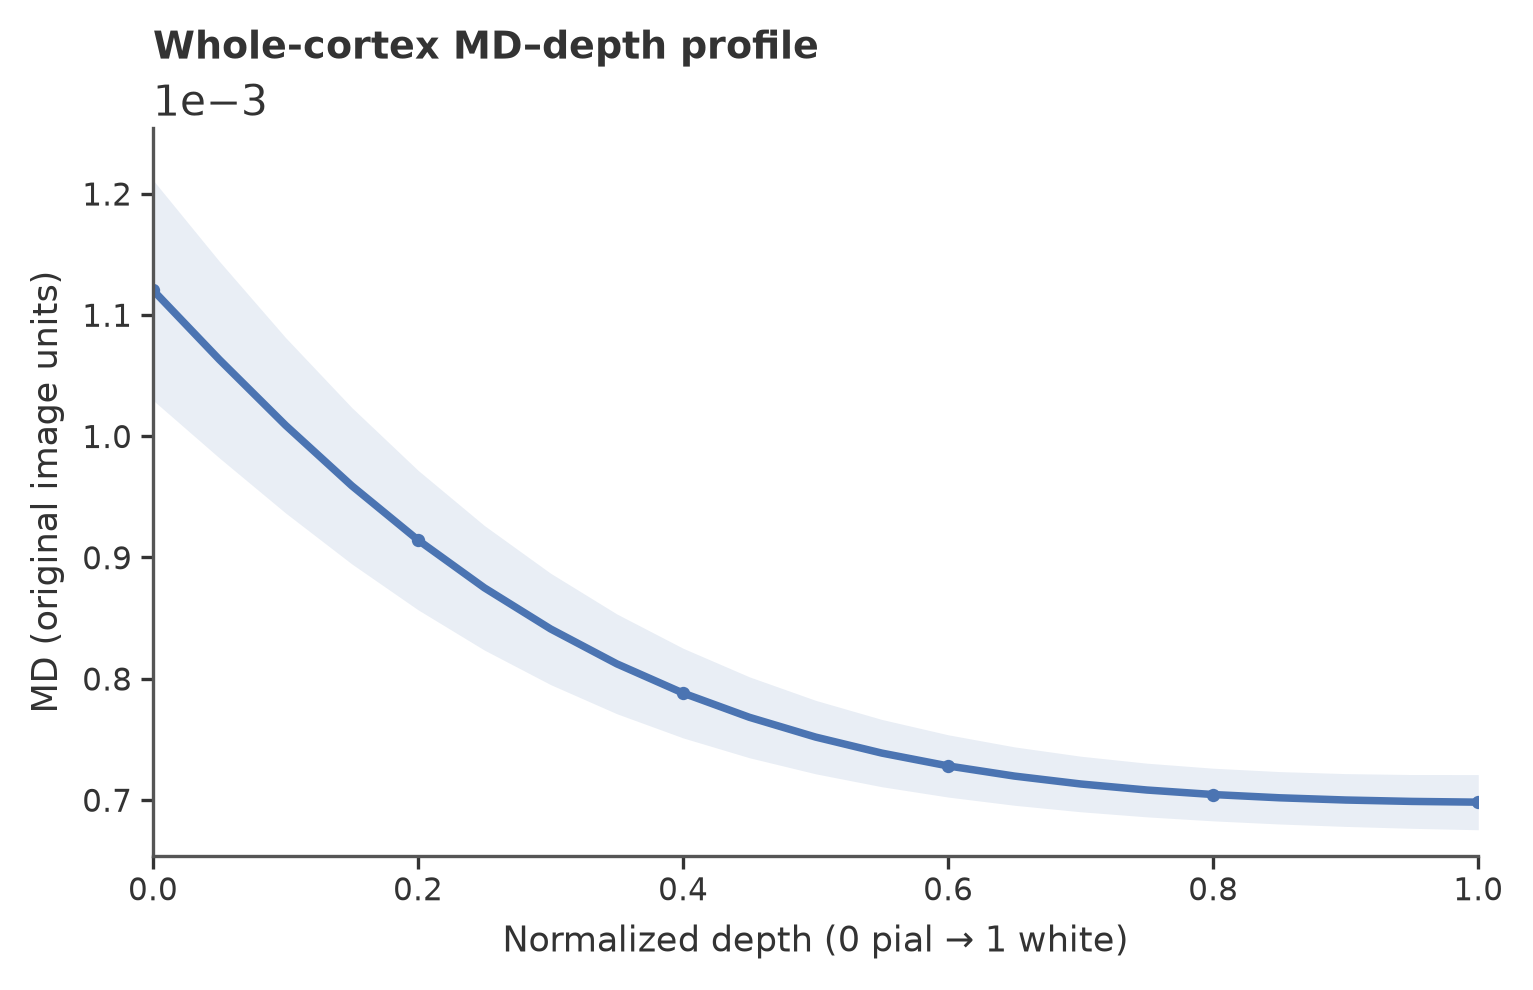

### P10/P50/P90 regional examples

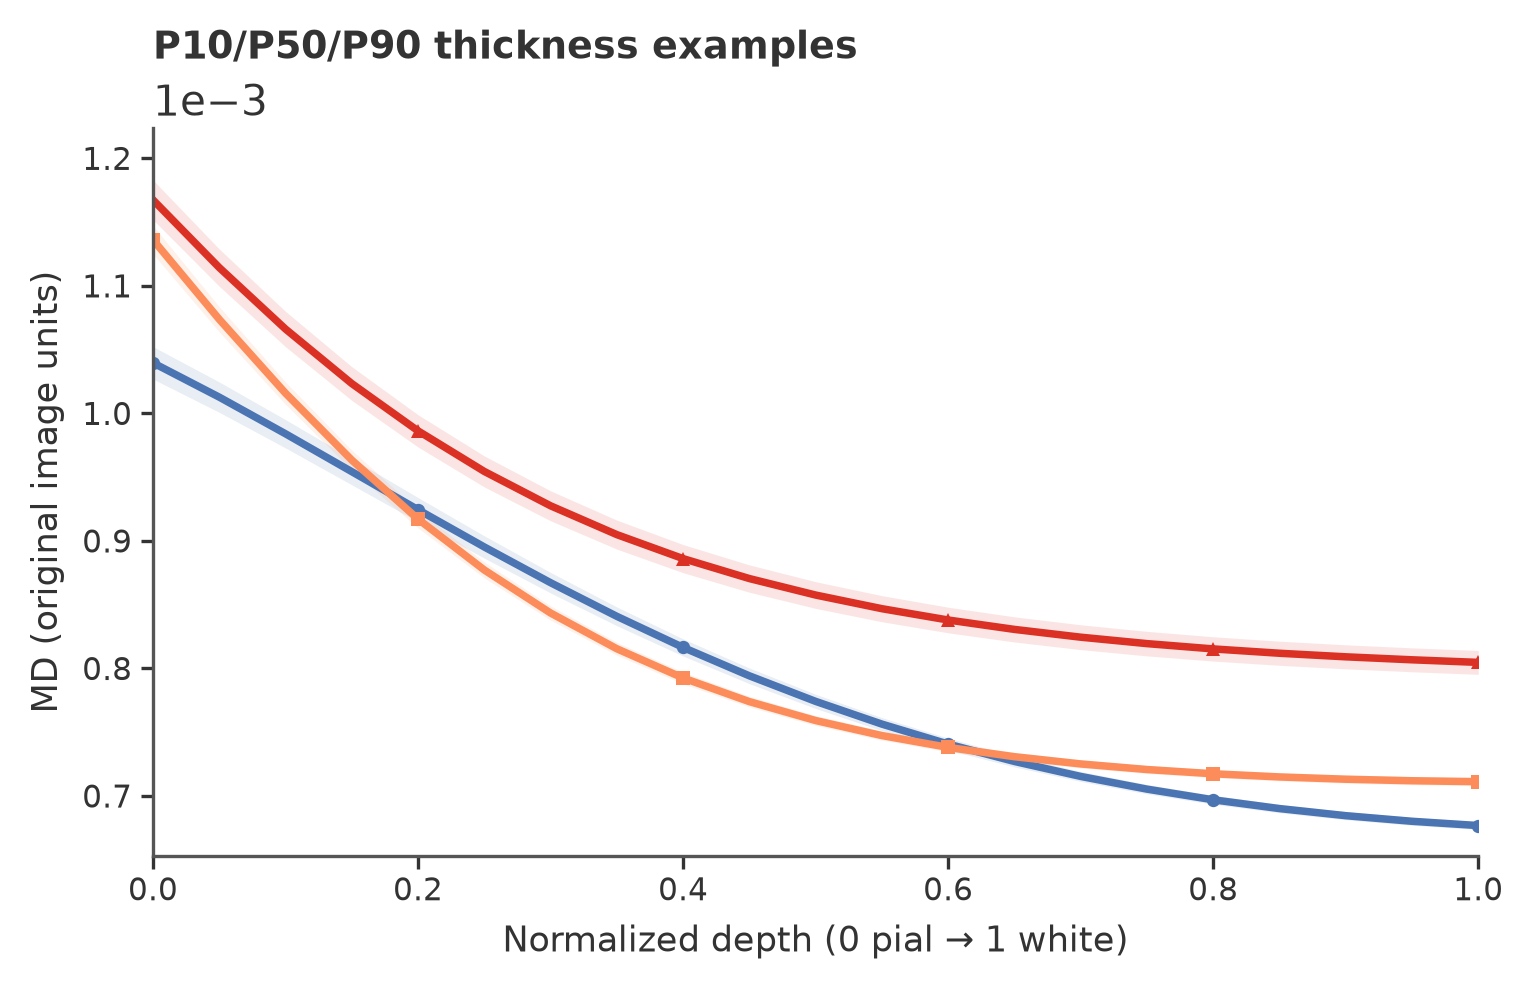

### P10/P50/P90 regional thickness distribution

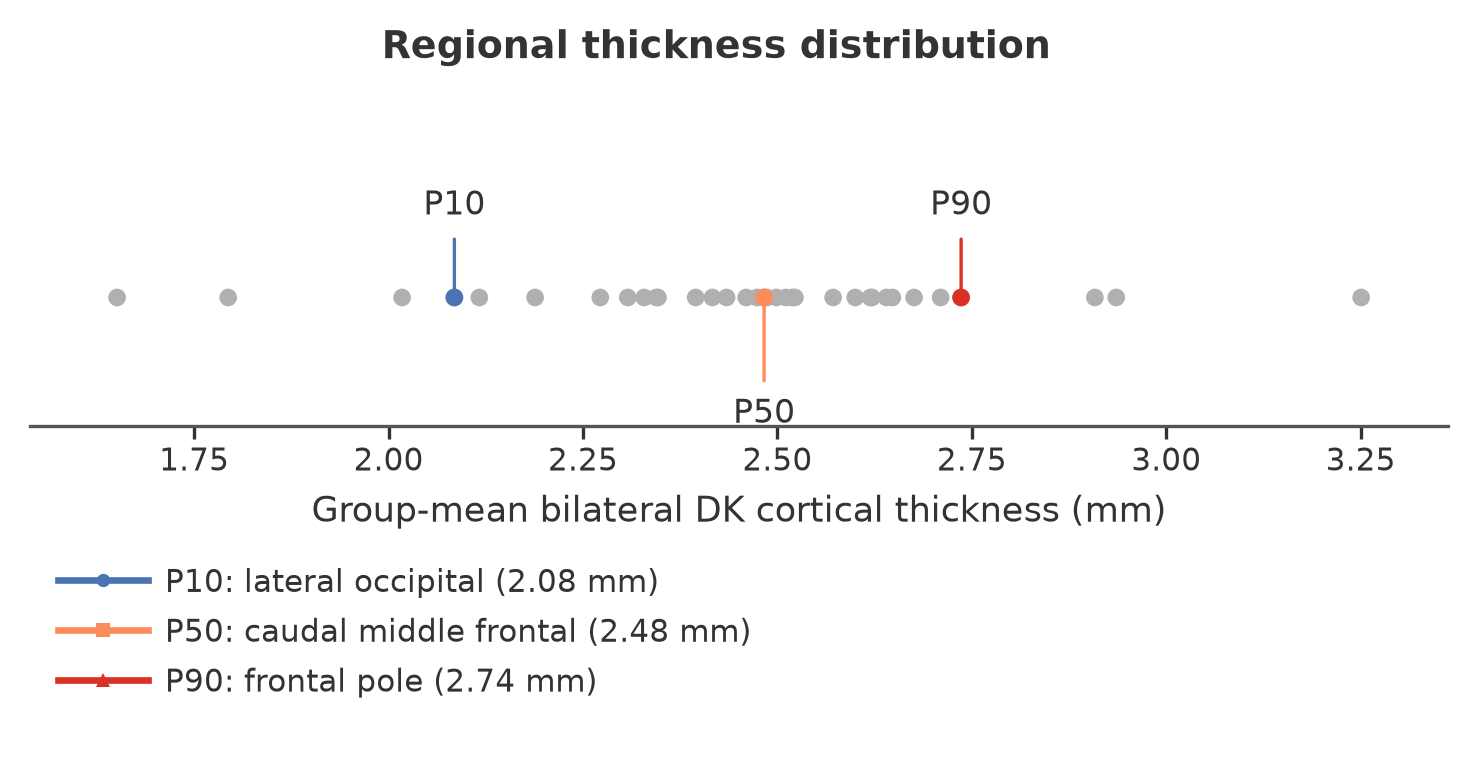

### Minimum/median/maximum regional examples

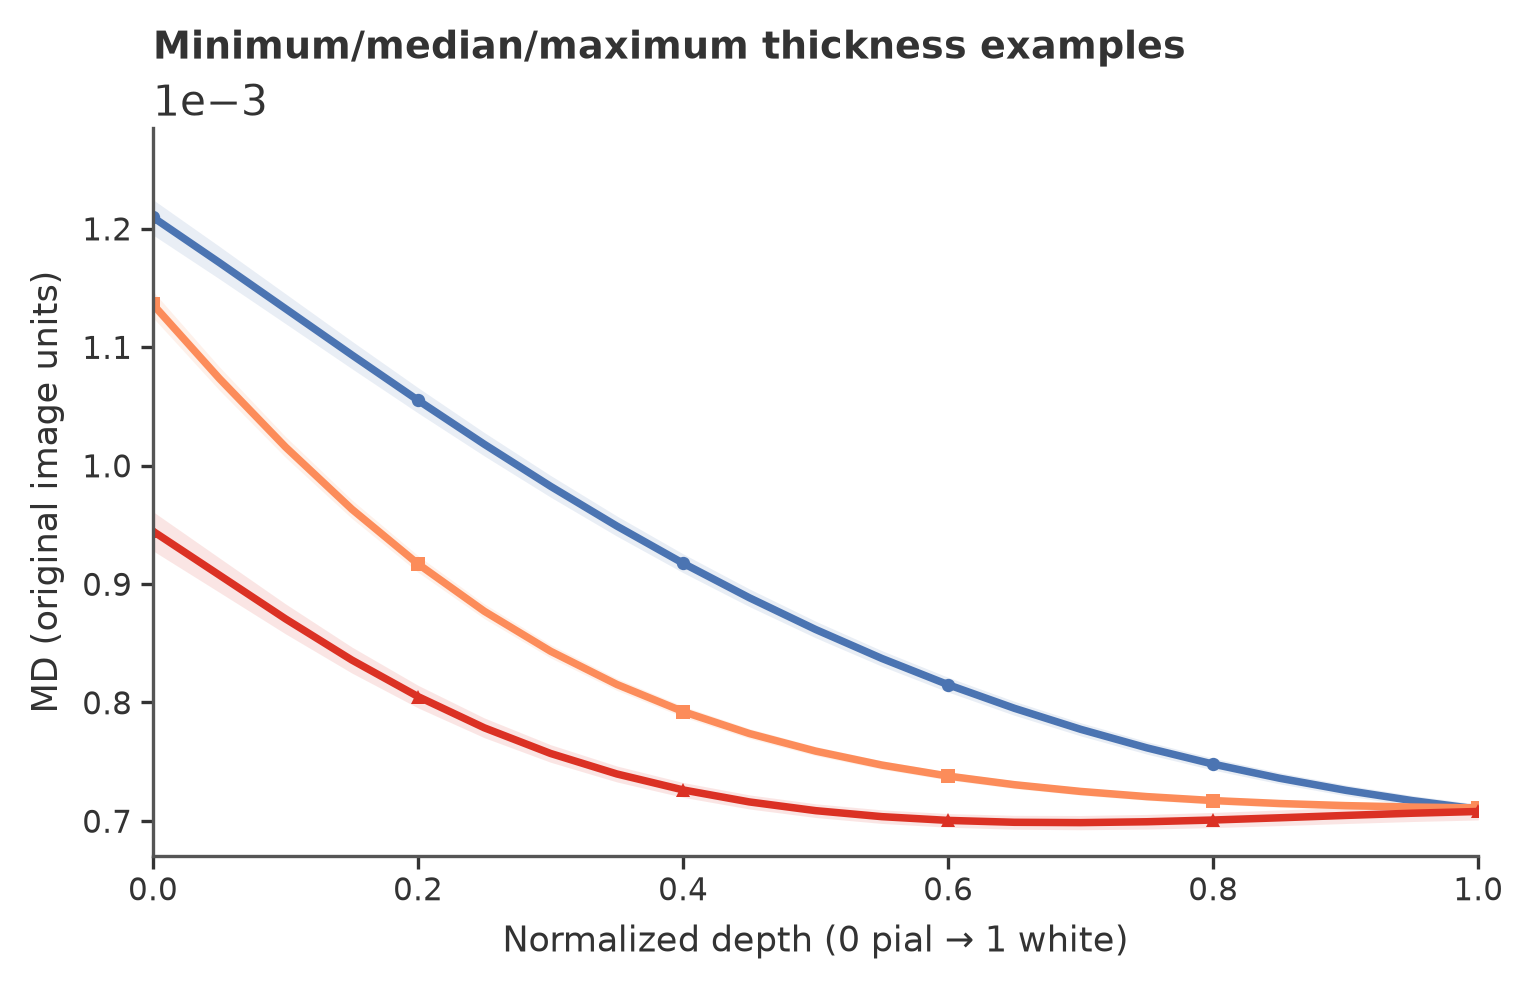

### Full-range regional thickness distribution

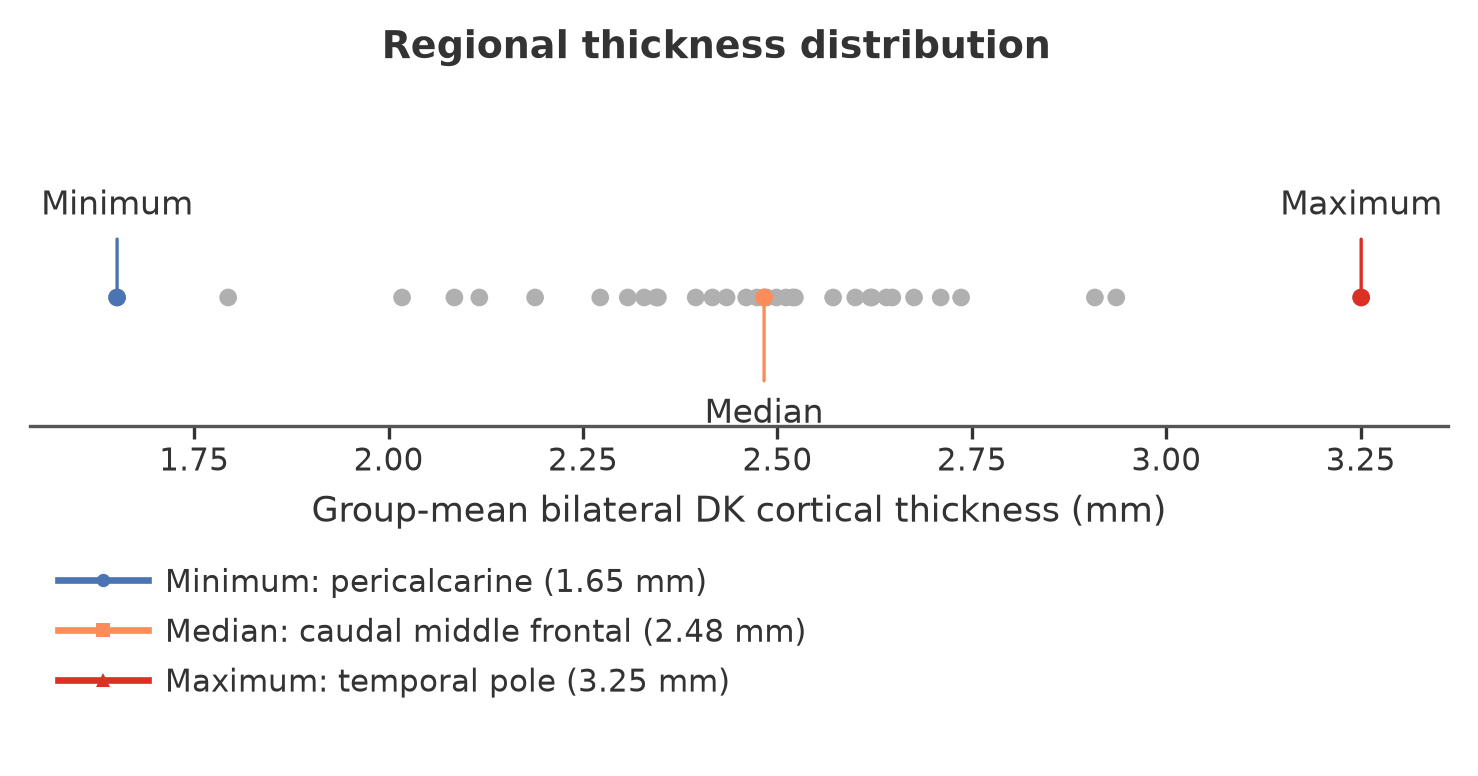

### Thickness-only selections

,region_name,selected_level,group_mean_thickness,thickness_percentile
3,lateraloccipital,thin,2.084601,9.090909
16,caudalmiddlefrontal,intermediate,2.482844,48.484848
30,frontalpole,thick,2.736183,90.909091


,region_name,extreme_level,group_mean_thickness,coverage_fraction
0,pericalcarine,minimum,1.650900,1.0
1,caudalmiddlefrontal,median,2.482844,1.0
2,temporalpole,maximum,3.250593,1.0


In [3]:
panel_a_manifest = json.loads((QC / 'figure3A_separate_plot_manifest.json').read_text())
assert panel_a_manifest['status'] == 'complete'
assert panel_a_manifest['whole_cortex_interval'] == 'Between-subject SD'
assert panel_a_manifest['regional_interval'].startswith('Two-sided 95% t confidence interval')
assert panel_a_manifest['selection_uses_md'] is False

panel_a_displays = [
    ('Whole-cortex mean MD–depth profile', 'Figure3A_01_whole_cortex_profile'),
    ('P10/P50/P90 regional examples', 'Figure3A_02_quantile_region_profiles'),
    ('P10/P50/P90 regional thickness distribution', 'Figure3A_03_quantile_selection_key'),
    ('Minimum/median/maximum regional examples', 'Figure3A_04_extreme_region_profiles'),
    ('Full-range regional thickness distribution', 'Figure3A_05_extreme_selection_key'),
]
for title, stem in panel_a_displays:
    path = FIGURES / f'{stem}.png'
    assert path.is_file(), path
    display(Markdown(f'### {title}'))
    display(Image(filename=str(path), width=760))

whole_cortex = pd.read_csv(TABLES / 'figure3A_whole_cortex_group_profile.csv')
assert len(whole_cortex) == 21 and whole_cortex.n_subjects.eq(N).all()
ranking = pd.read_csv(TABLES / 'figure3A_region_thickness_ranking.csv')
selection = ranking.loc[ranking.selected_for_figure3].sort_values('target_percentile')
extreme_qc = pd.read_csv(QC / 'figure3A_extreme_region_coverage_qc.csv')
assert extreme_qc.complete_21_depth_grid.all() and extreme_qc.no_imputation.all()
display(Markdown('### Thickness-only selections'))
display(selection[['region_name', 'selected_level', 'group_mean_thickness', 'thickness_percentile']])
display(extreme_qc[['region_name', 'extreme_level', 'group_mean_thickness', 'coverage_fraction']])

## B · Main profile-shape components

Each valid 21-depth profile is centered by its own depth mean; PCA then uses equal total weight per subject. The loading curve shows only PC1 and PC2. The separate explained-variance chart retains PC1–PC5.

The cortical maps focus on PC1 and PC2. Each PC has its own zero-centered symmetric color range so that both spatial patterns remain visible; the four hemisphere/view panels within a PC share one range, and that same PC-specific range is reused in D. Therefore color intensity must not be compared between PC1 and PC2 as an absolute amplitude measure.

### PC1 and PC2 loading curves

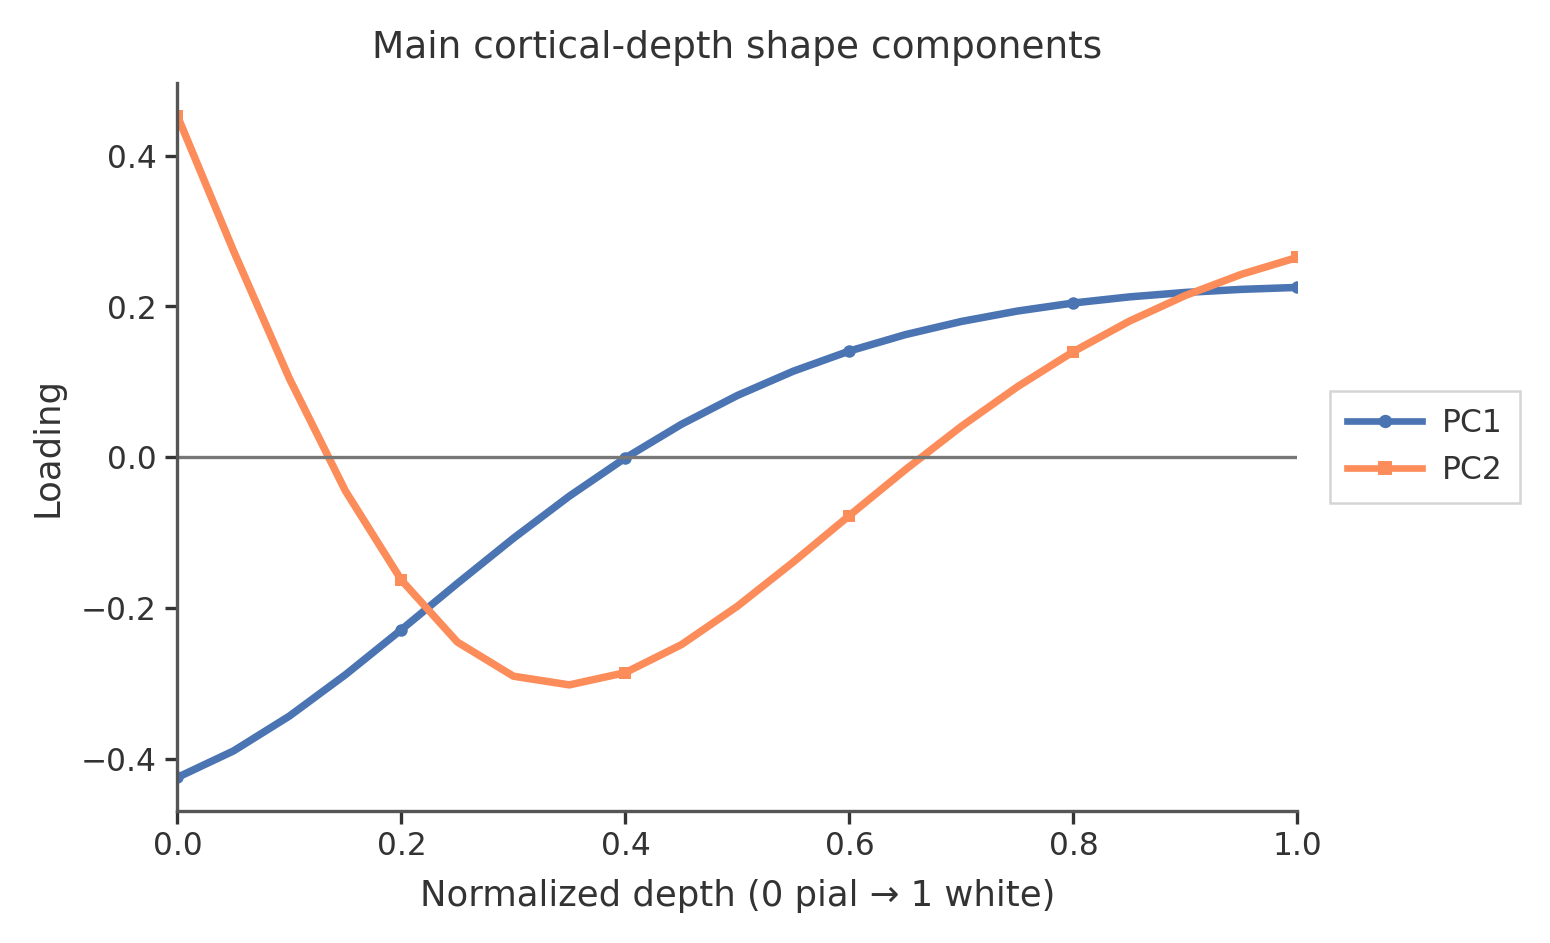

### Explained variance

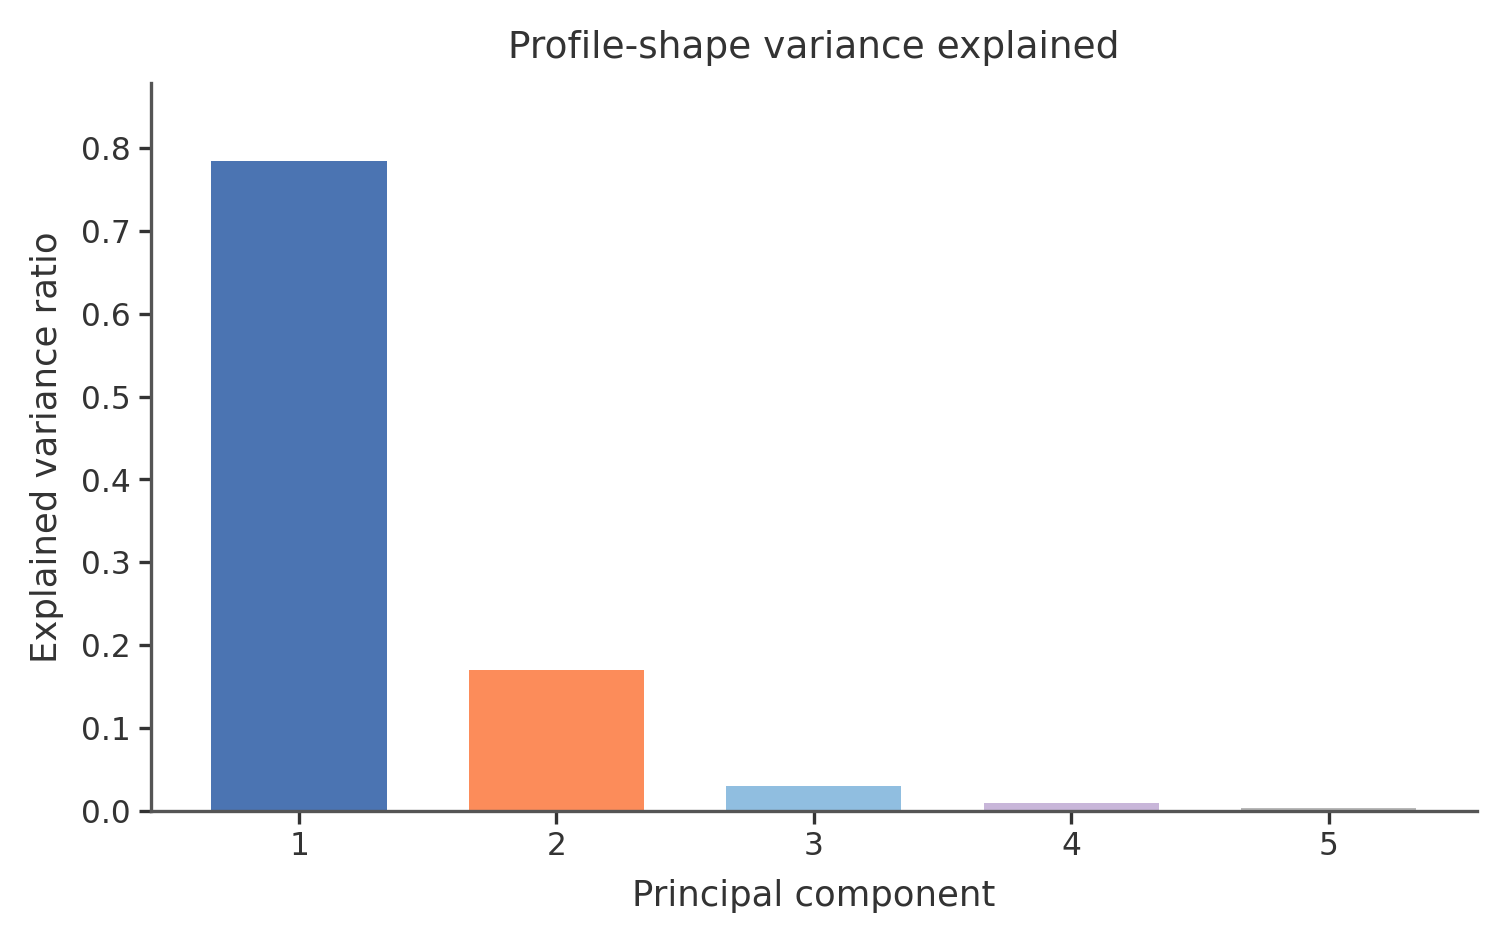

,component,explained_variance_ratio,cumulative_explained_variance
0,1,0.784931,0.784931
1,2,0.169465,0.954395
2,3,0.029866,0.984261
3,4,0.009292,0.993553
4,5,0.003310,0.996863


### PC1 and PC2 cortical score maps

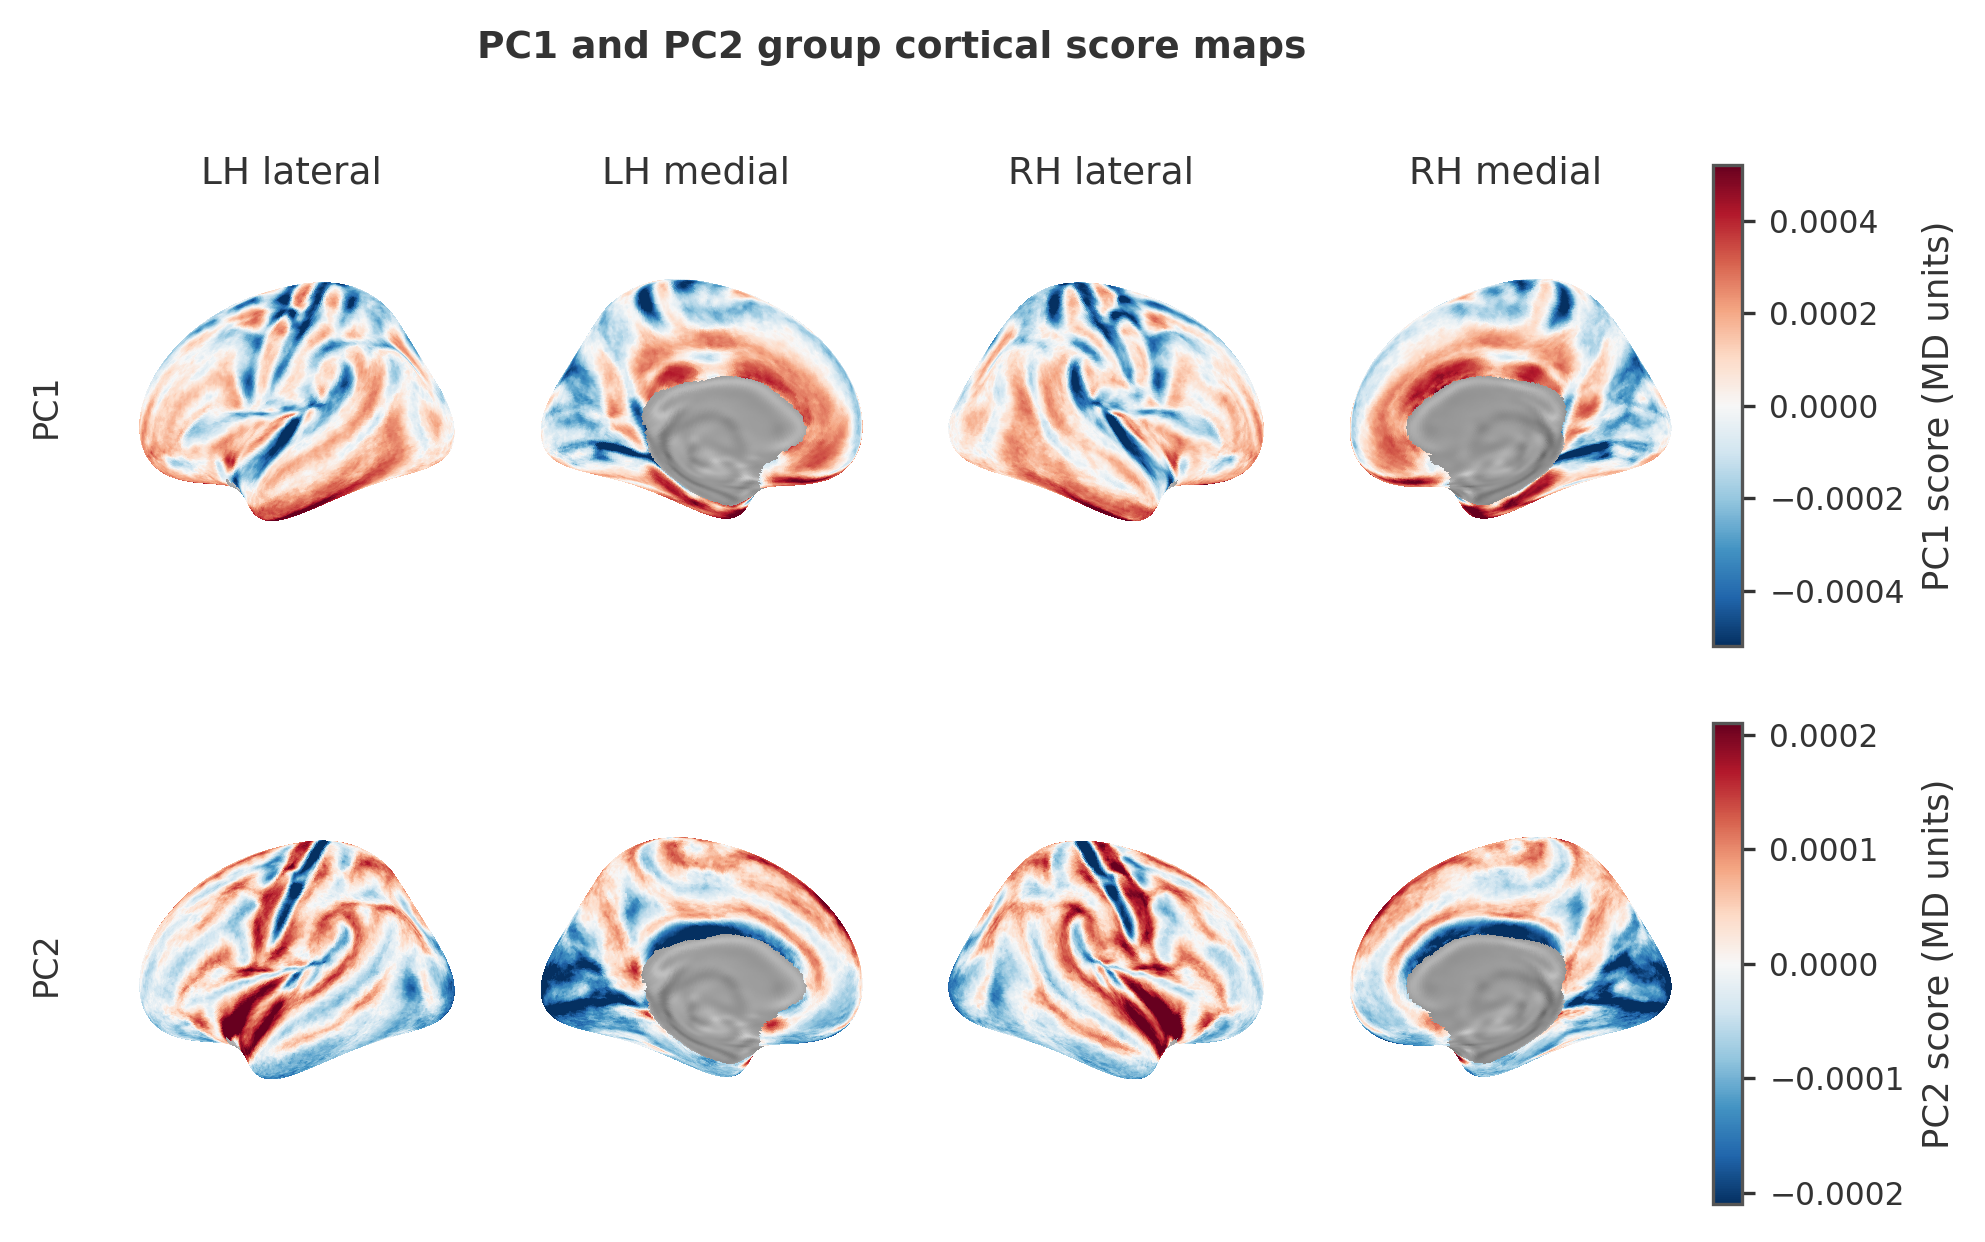

**Caption.** PC1 and PC2 use separate colorbar ranges so that the spatial pattern of each component remains visible. Each range is symmetric about zero, and all hemispheres and views within a PC share that range. Both use the same RdBu_r colors as Figure 2. Because the two PCs have different numeric ranges, color intensity must not be used to compare their absolute score amplitudes; quantitative score metrics provide that comparison.


In [4]:
loadings = pd.read_csv(TABLES / 'figure3B_pca_loadings.csv')
variance = pd.read_csv(TABLES / 'figure3B_pca_explained_variance.csv')
tracking = json.loads((QC / 'figure3_fixed_component_tracking.json').read_text())
assert tracking['status'] == 'complete' and tracking['n_subjects'] == N
assert tracking['loading_source'] == 'Original frozen PCA loadings'
assert np.allclose(loadings.normalized_depth, np.linspace(0, 1, 21))

display(Markdown('### PC1 and PC2 loading curves'))
display(Image(filename=str(FIGURES / 'Figure3B_01_PC1_PC2_loadings.png'), width=760))
display(Markdown('### Explained variance'))
display(Image(filename=str(FIGURES / 'Figure3B_02_explained_variance.png'), width=760))
display(variance.loc[variance.component.between(1, 5),
                     ['component', 'explained_variance_ratio', 'cumulative_explained_variance']])
display(Markdown('### PC1 and PC2 cortical score maps'))
display(Image(filename=str(FIGURES / 'Figure3B_03_PC1_PC2_group_score_maps.png'), width=900))
display(Markdown('**Caption.** ' +
                 (FIGURES / 'Figure3B_PC1_PC2_group_score_maps_caption.txt').read_text()))

## C · Thickness association

The first result summarizes, for each subject, the cortical spatial Spearman correlation between thickness and the fixed PC1 or PC2 score; diamonds and error bars mark the median and its 95% subject-bootstrap CI. The second result gives the depth-specific thickness partial $R^2$ from subject-fixed-effects models, answering where thickness explains more MD variance. The signed $\beta$ curve is retained in the supplement because it answers direction rather than explained variance.

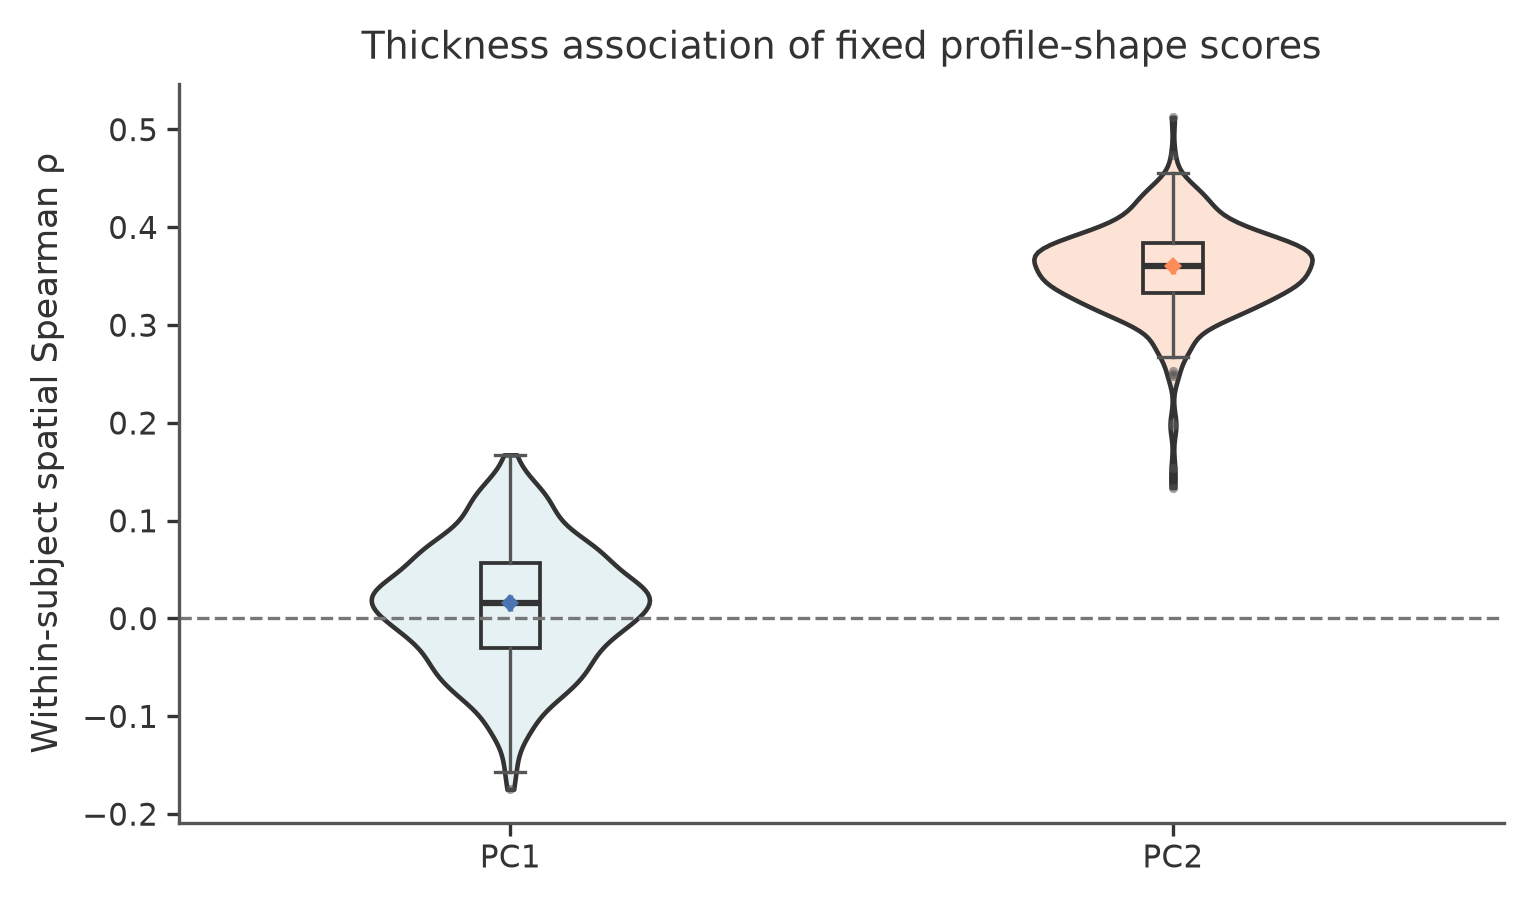

,component,median_rho,rho_q25,rho_q75,median_rho_ci95_lower,median_rho_ci95_upper
0,PC1,0.015485,-0.029993,0.056713,0.007180,0.023901
1,PC2,0.360157,0.332246,0.384033,0.352422,0.364762


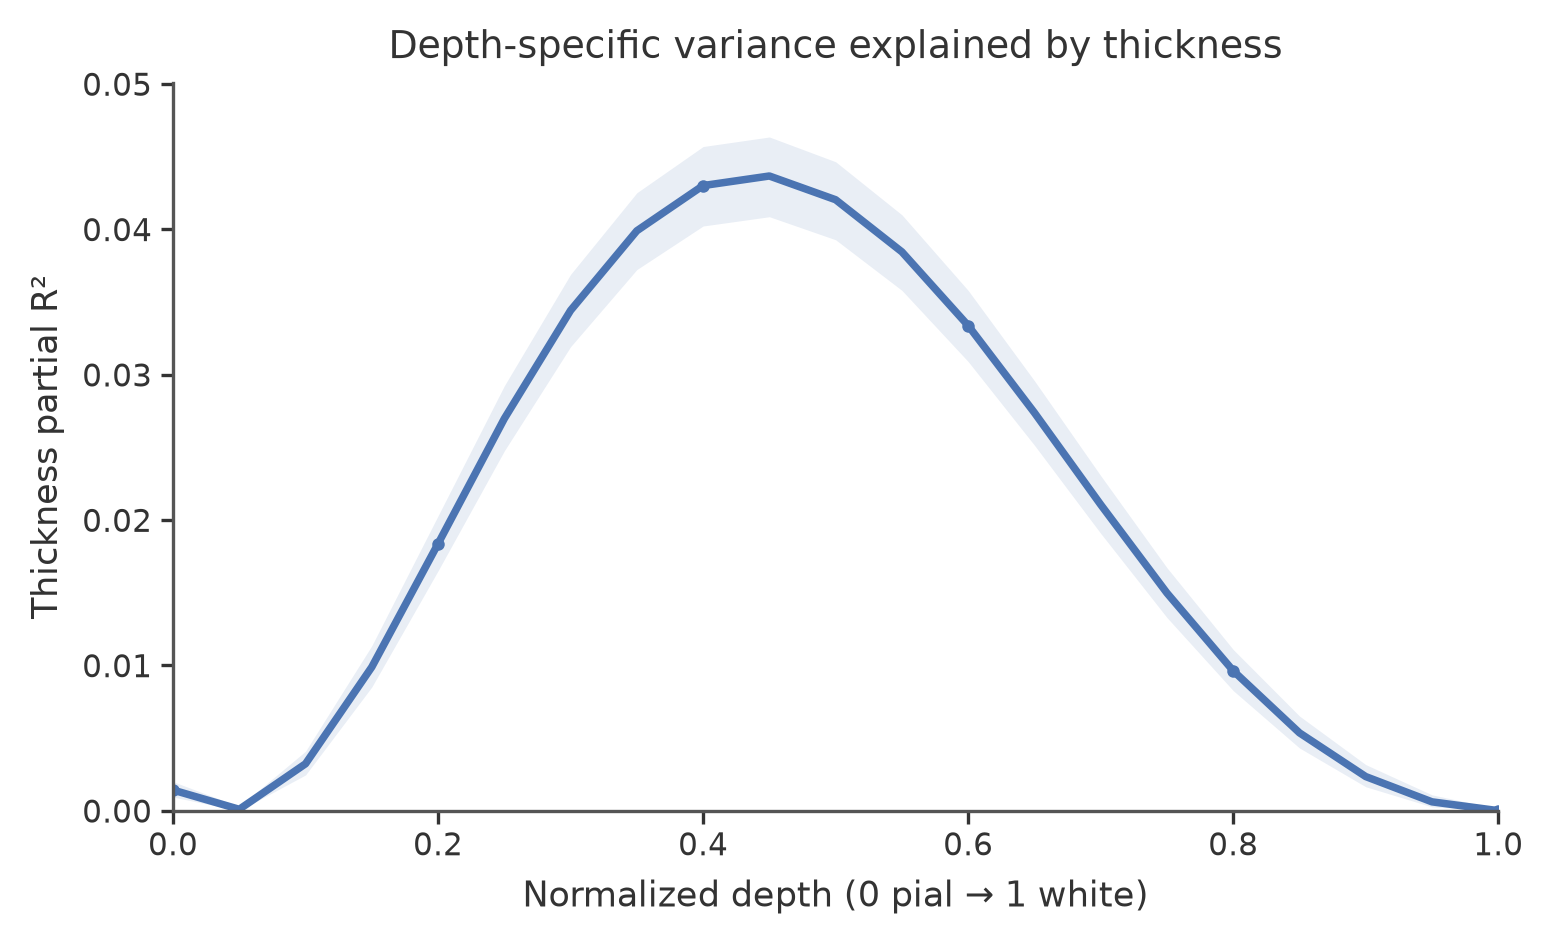

,depth_index,normalized_depth,partial_r2,partial_r2_ci95_lower,partial_r2_ci95_upper
0,0,0.00,0.001423,9.432869e-04,0.002002
5,5,0.25,0.026974,2.475801e-02,0.029233
10,10,0.50,0.042033,3.927953e-02,0.044646
15,15,0.75,0.014978,1.329239e-02,0.016716
20,20,1.00,0.000007,2.523968e-08,0.000128


In [5]:
PC_COMPARISON = OUTPUT / 'pc1_pc2_thickness'
pc_summary = pd.read_csv(PC_COMPARISON / 'component_correlation_summary.csv')
assert pc_summary.n_subjects.eq(N).all()
display(Image(filename=str(FIGURES / 'Figure3C_01_PC1_PC2_thickness_correlations.png'), width=760))
display(pc_summary[['component', 'median_rho', 'rho_q25', 'rho_q75',
                    'median_rho_ci95_lower', 'median_rho_ci95_upper']])

effects = pd.read_csv(TABLES / 'figure3C_depth_specific_thickness_effect.csv')
assert len(effects) == 21
display(Image(filename=str(FIGURES / 'Figure3C_02_thickness_partial_r2.png'), width=760))
display(effects.loc[effects.depth_index.isin([0, 5, 10, 15, 20]),
                    ['depth_index', 'normalized_depth', 'partial_r2',
                     'partial_r2_ci95_lower', 'partial_r2_ci95_upper']])

### C supplement · Curvature association check

This supplementary check asks whether the fixed PC1/PC2 score patterns also follow cortical folding. Native subject-specific FreeSurfer `lh.curv` and `rh.curv` are mapped to fsaverage with the same Option 3 triangle IDs and barycentric weights used for thickness and MD.

FreeSurfer's signed curvature convention is **positive for sulcal/folded-in locations and negative for gyral/folded-out locations** ([FreeSurfer documentation](https://surfer.nmr.mgh.harvard.edu/fswiki/UserContributions/FAQ)). Signed curvature is the primary check. Absolute curvature is secondary and is calculated as the weighted mean of absolute native-vertex curvature, not the absolute value after signed interpolation.

For each subject and fixed component, the analysis reports (1) spatial Spearman correlation and (2) the curvature coefficient and partial $R^2$ from `PC score ~ thickness + curvature`. Group intervals use 10,000 subject bootstrap resamples. This is an association check only: it cannot distinguish anatomical organization from sampling geometry, and curvature is not removed from the primary analysis.

#### Spatial association with curvature

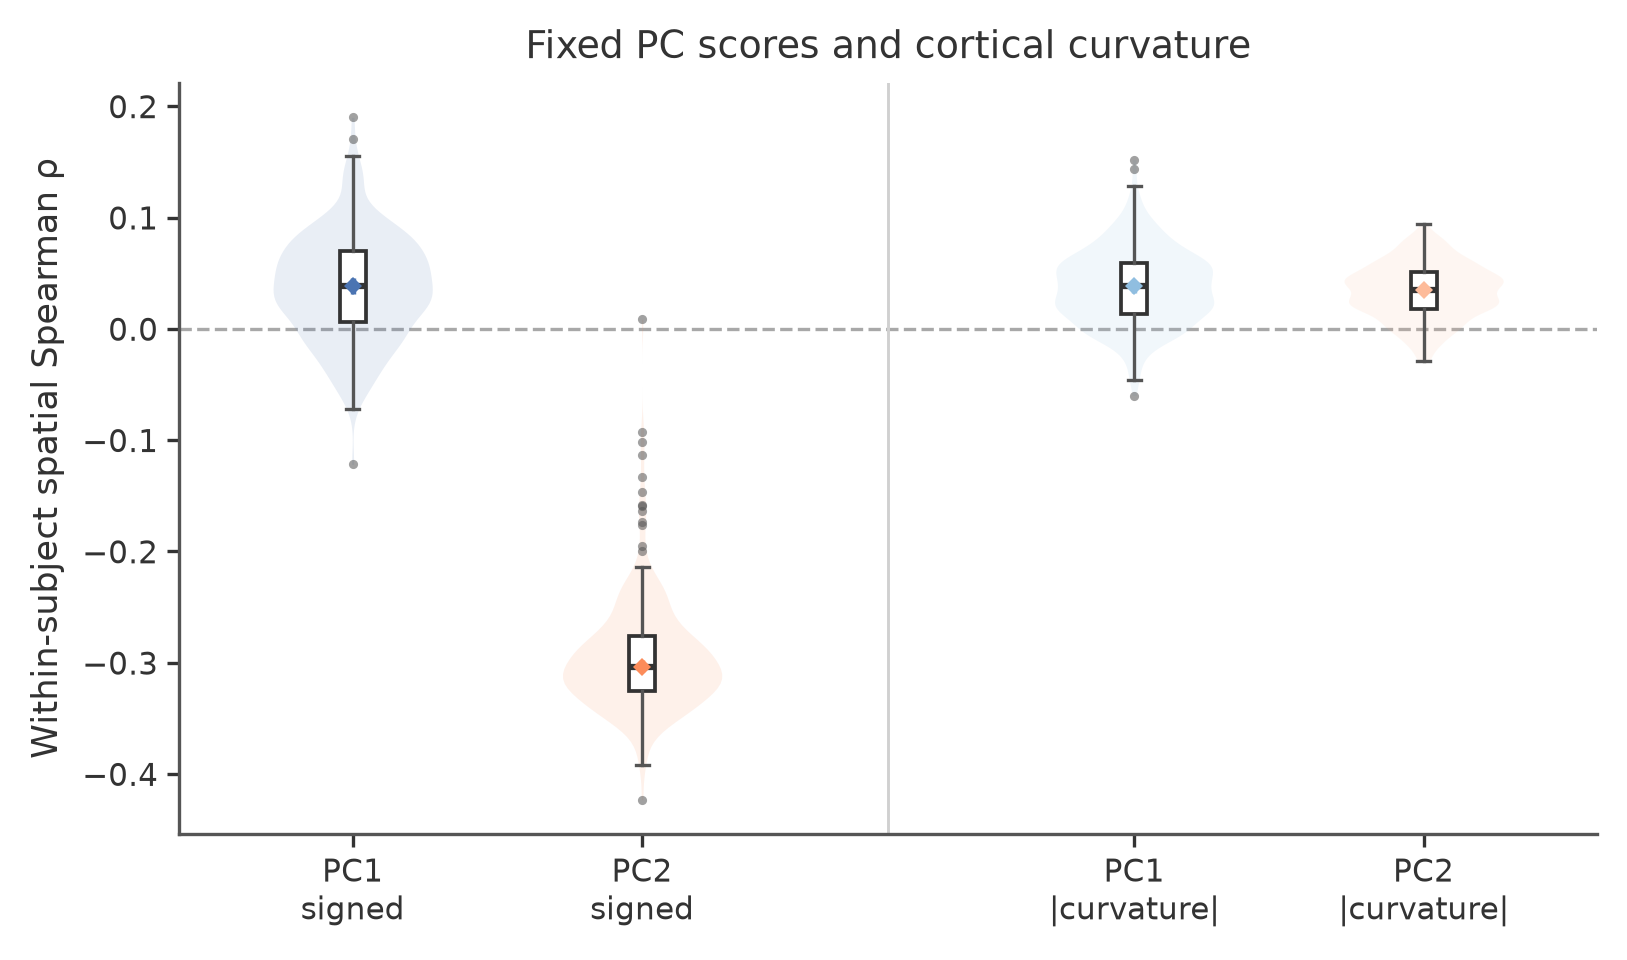

#### Curvature coefficient after controlling thickness

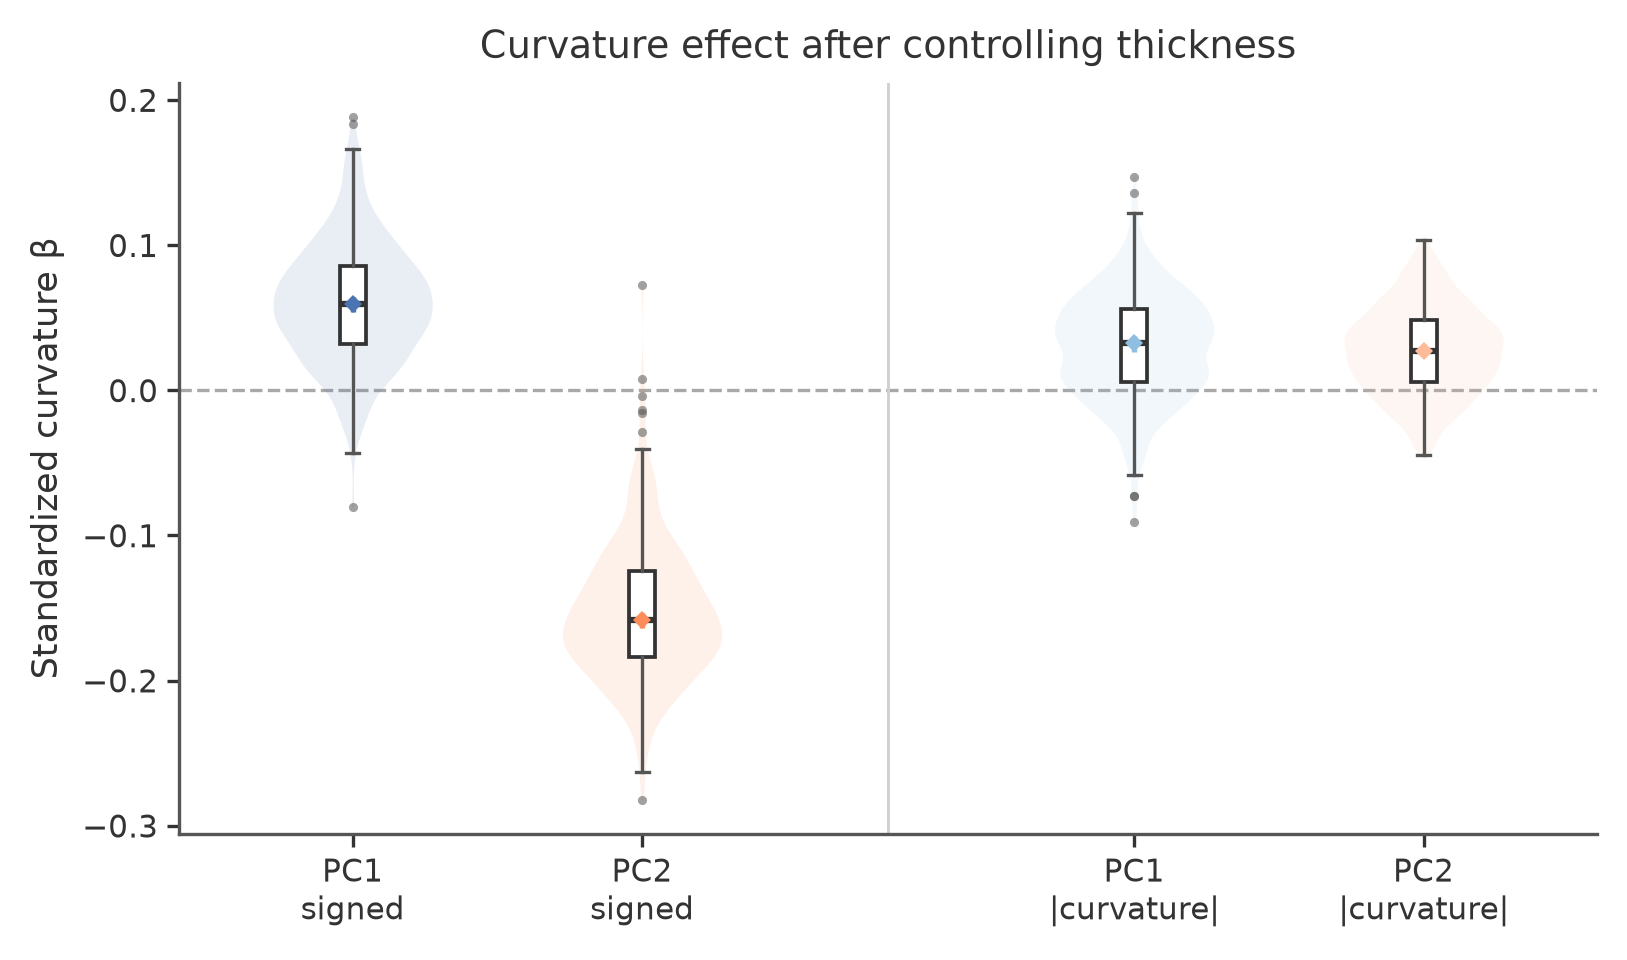

#### Additional variance explained beyond thickness

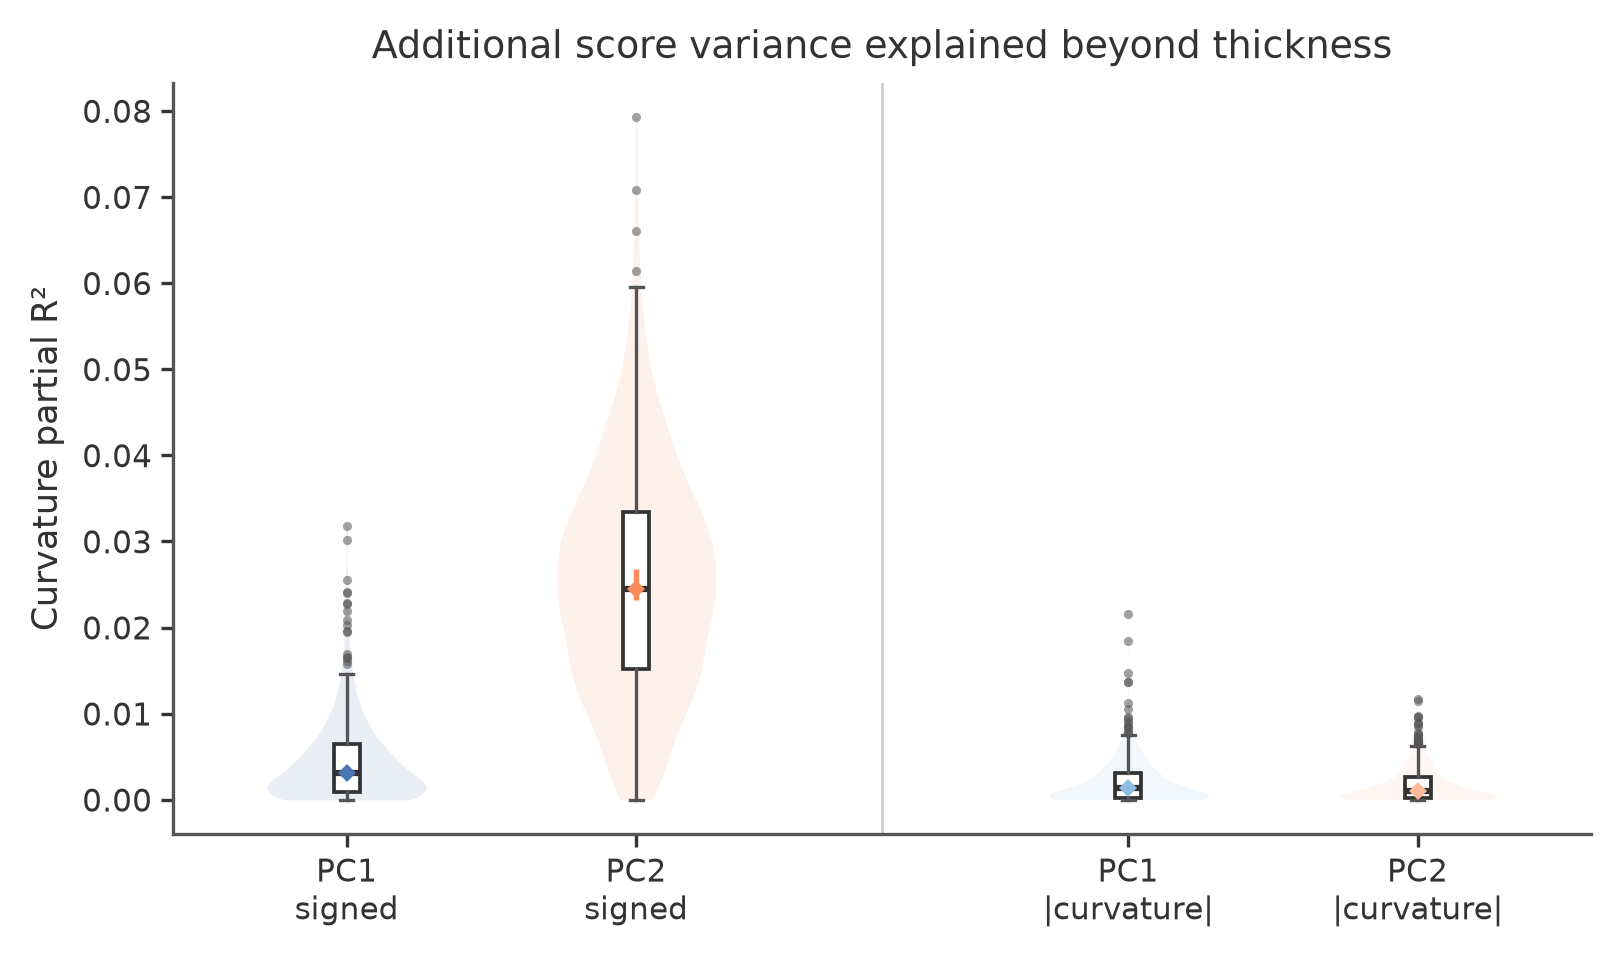

,component,curvature_metric,metric,median,ci95_lower,ci95_upper,q25,q75
0,PC1,signed,spatial_spearman_rho,0.038628,0.031301,0.045384,0.005962,0.070098
1,PC1,signed,standardized_beta_curvature,0.059586,0.053741,0.064544,0.031987,0.085736
2,PC1,signed,partial_r2_curvature,0.003136,0.002607,0.003775,0.000926,0.006501
3,PC1,absolute,spatial_spearman_rho,0.038252,0.031948,0.042000,0.013785,0.059629
4,PC1,absolute,standardized_beta_curvature,0.032876,0.026687,0.037603,0.005488,0.055796
5,PC1,absolute,partial_r2_curvature,0.001345,0.000993,0.001573,0.000217,0.003166
6,PC2,signed,spatial_spearman_rho,-0.303707,-0.308594,-0.297481,-0.325192,-0.276306
7,PC2,signed,standardized_beta_curvature,-0.158265,-0.164094,-0.153620,-0.183785,-0.124847
8,PC2,signed,partial_r2_curvature,0.024522,0.023234,0.026773,0.015158,0.033373
9,PC2,absolute,spatial_spearman_rho,0.034790,0.030235,0.039363,0.017743,0.051238


#### Data-driven interpretation

PC1, signed curvature: median spatial rho 0.039 (95% CI 0.031 to 0.045); median standardized curvature beta after thickness adjustment 0.060 (95% CI 0.054 to 0.065); median curvature partial R2 0.003 (95% CI 0.003 to 0.004).
PC2, signed curvature: median spatial rho -0.304 (95% CI -0.309 to -0.297); median standardized curvature beta after thickness adjustment -0.158 (95% CI -0.164 to -0.154); median curvature partial R2 0.025 (95% CI 0.023 to 0.027).
PC1, absolute curvature: median spatial rho 0.038 (95% CI 0.032 to 0.042); median standardized curvature beta after thickness adjustment 0.033 (95% CI 0.027 to 0.038); median curvature partial R2 0.001 (95% CI 0.001 to 0.002).
PC2, absolute curvature: median spatial rho 0.035 (95% CI 0.030 to 0.039); median standardized curvature beta after thickness adjustment 0.027 (95% CI 0.023 to 0.032); median curvature partial R2 0.001 (95% CI 0.001 to 0.001).

Associations are observational. They do not distinguish anatomical organization from sampling geometry, and curvature is not removed from the primary Figure 3 analysis.


In [6]:
CURVATURE = OUTPUT / 'curvature_supplement'
curvature_status = json.loads((CURVATURE / 'complete.json').read_text())
assert curvature_status['status'] == 'complete'
assert curvature_status['n_subjects'] == N
assert curvature_status['statistical_unit'] == 'subject'
assert curvature_status['primary_analysis_changed'] is False
assert curvature_status['legacy_signed_max_abs_difference'] == 0
assert curvature_status['legacy_absolute_max_abs_difference'] == 0
curvature_summary = pd.read_csv(CURVATURE / 'pc_curvature_group_summary.csv')
assert len(curvature_summary) == 12

for title, stem in [
    ('Spatial association with curvature', 'Figure3S_C01_PC_curvature_spatial_rho'),
    ('Curvature coefficient after controlling thickness', 'Figure3S_C02_PC_curvature_adjusted_beta'),
    ('Additional variance explained beyond thickness', 'Figure3S_C03_PC_curvature_partial_r2'),
]:
    display(Markdown(f'#### {title}'))
    display(Image(filename=str(FIGURES / f'{stem}.png'), width=780))

display(curvature_summary[['component', 'curvature_metric', 'metric', 'median',
                           'ci95_lower', 'ci95_upper', 'q25', 'q75']])
display(Markdown('#### Data-driven interpretation'))
display(Markdown((FIGURES / 'Figure3S_C_curvature_interpretation.txt').read_text()))

## D · What remains after thickness adjustment

The adjusted curves use the same regions, colors, 95% CI ribbons, and coordinate ranges as their A counterparts:

$$MD^{adj}_{s,v,d}=MD_{s,v,d}-\beta_d(T_{s,v}-\bar T_s).$$

The whole-cortex curve is not repeated: within each subject and depth, the mean adjustment is zero because thickness is centered over the same valid vertices, so the whole-cortex mean is preserved by construction.

For shape tracking, the **original PC1/PC2 loadings and original PCA centering reference are fixed**. PCA is not refit after adjustment. Within each PC, raw and adjusted maps use one fixed zero-centered symmetric range across both conditions, hemispheres and views. PC1 and PC2 retain separate ranges, so cross-PC amplitude comparison relies on quantitative metrics rather than color intensity. Pattern retention is measured by raw–adjusted spatial correlation; amplitude retention is measured by the adjusted/raw spatial SD ratio.

### P10/P50/P90 after thickness adjustment

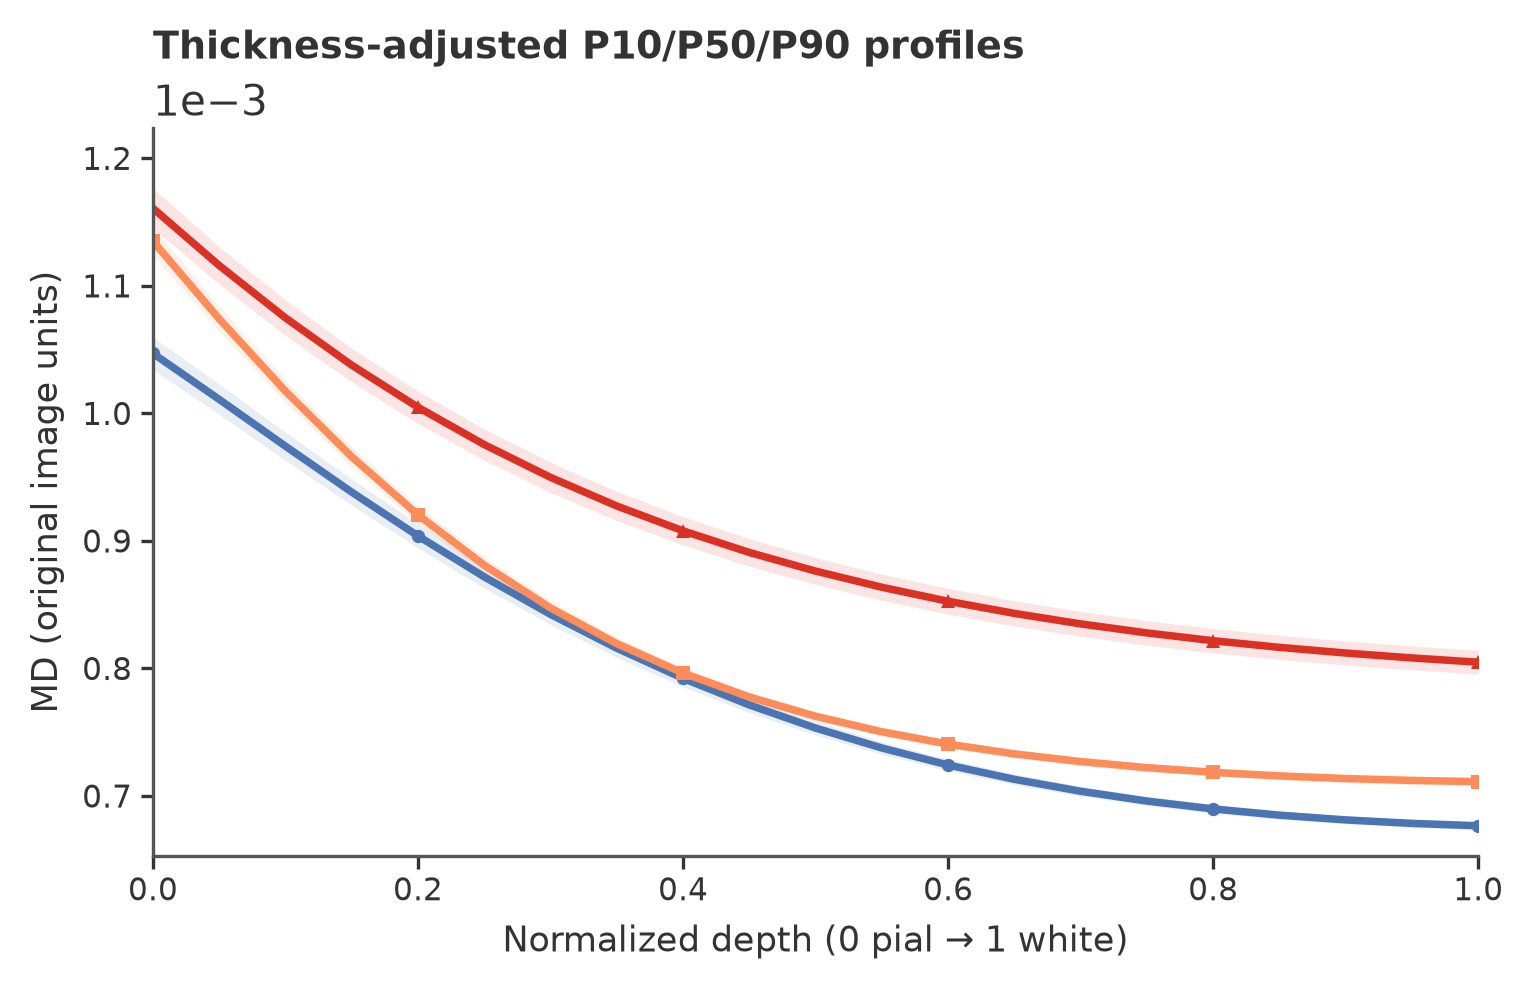

### Minimum/median/maximum after thickness adjustment

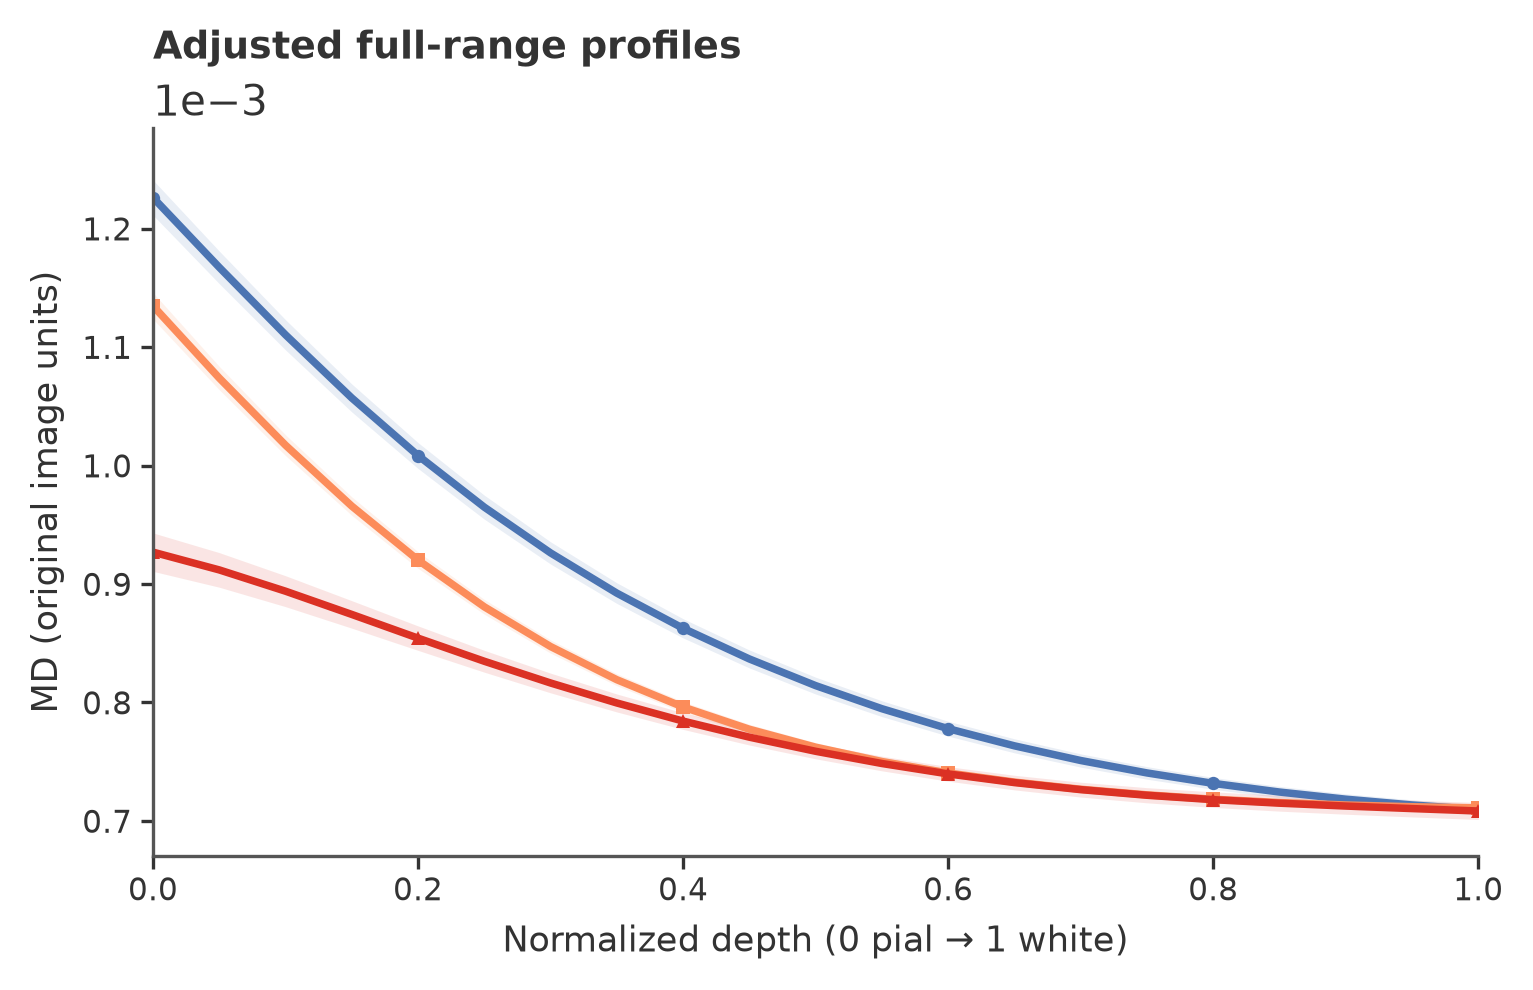

### Fixed-component cortical maps

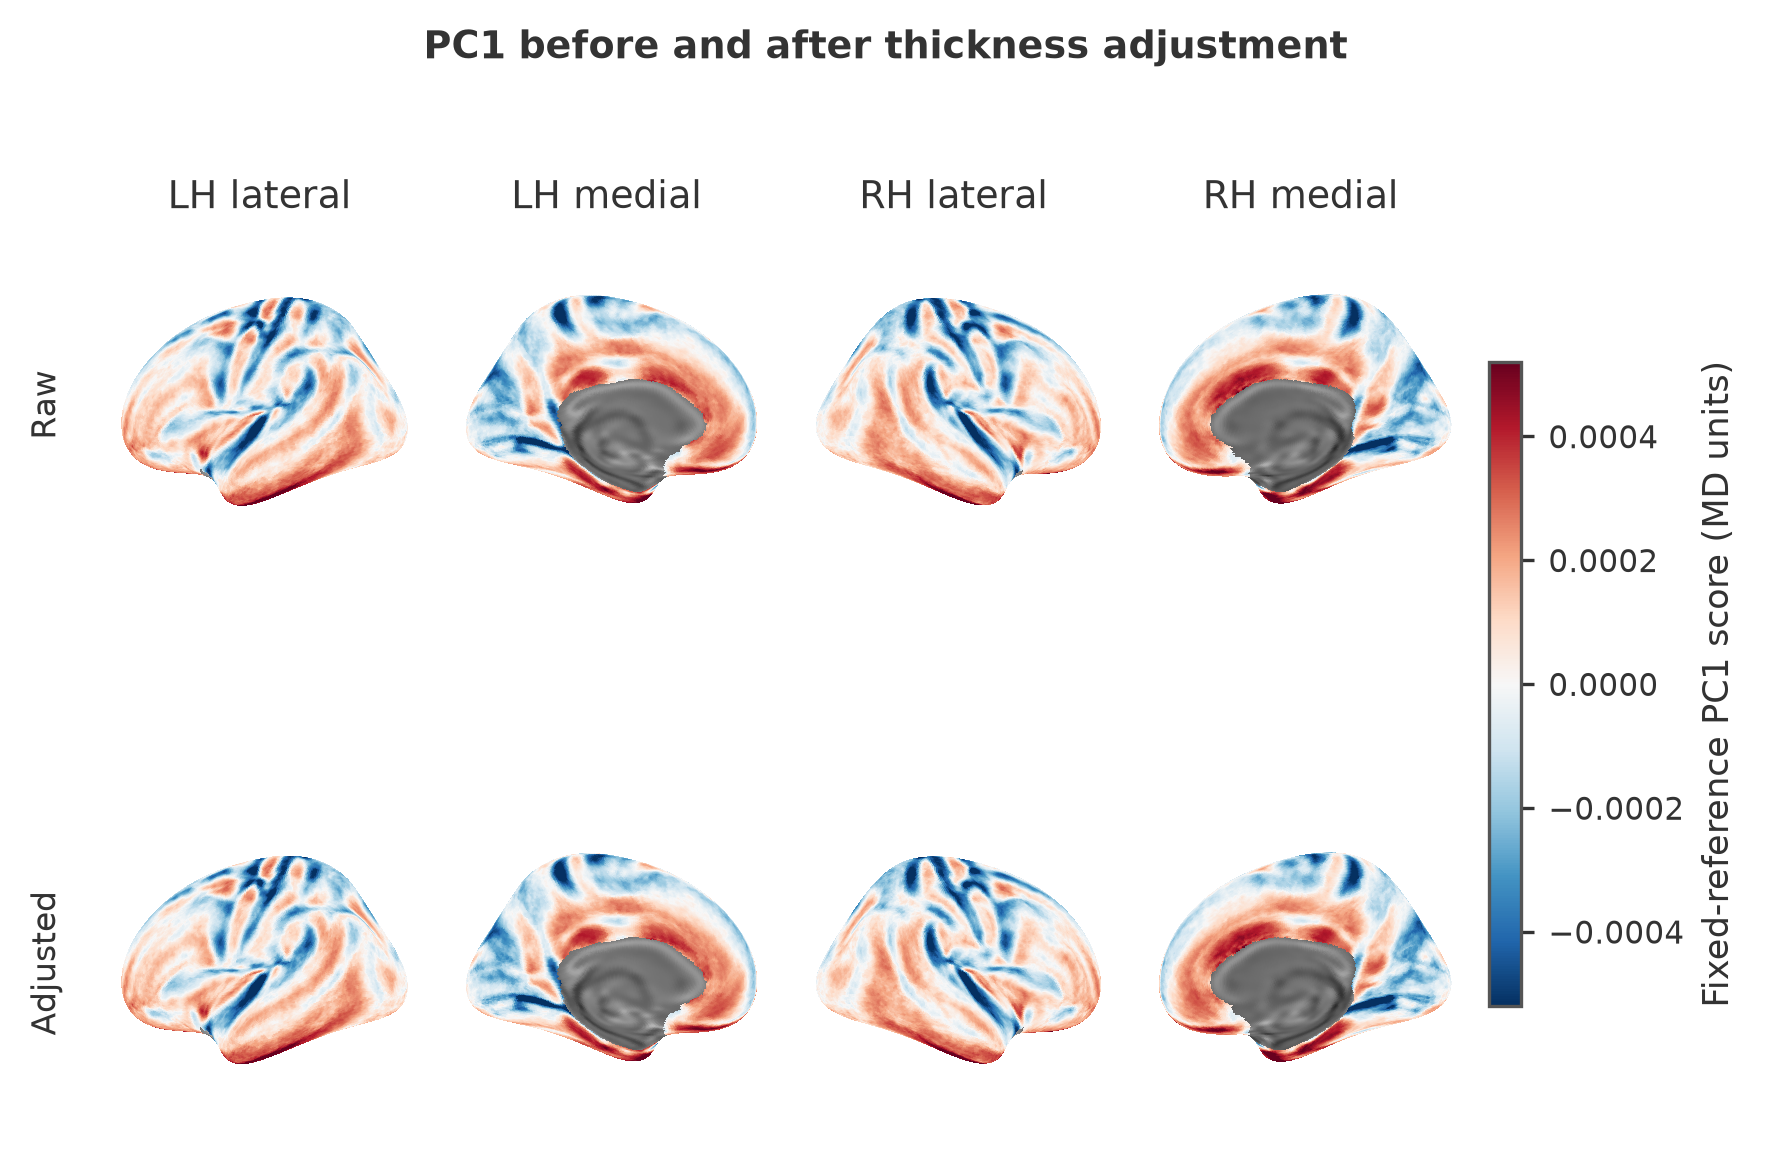

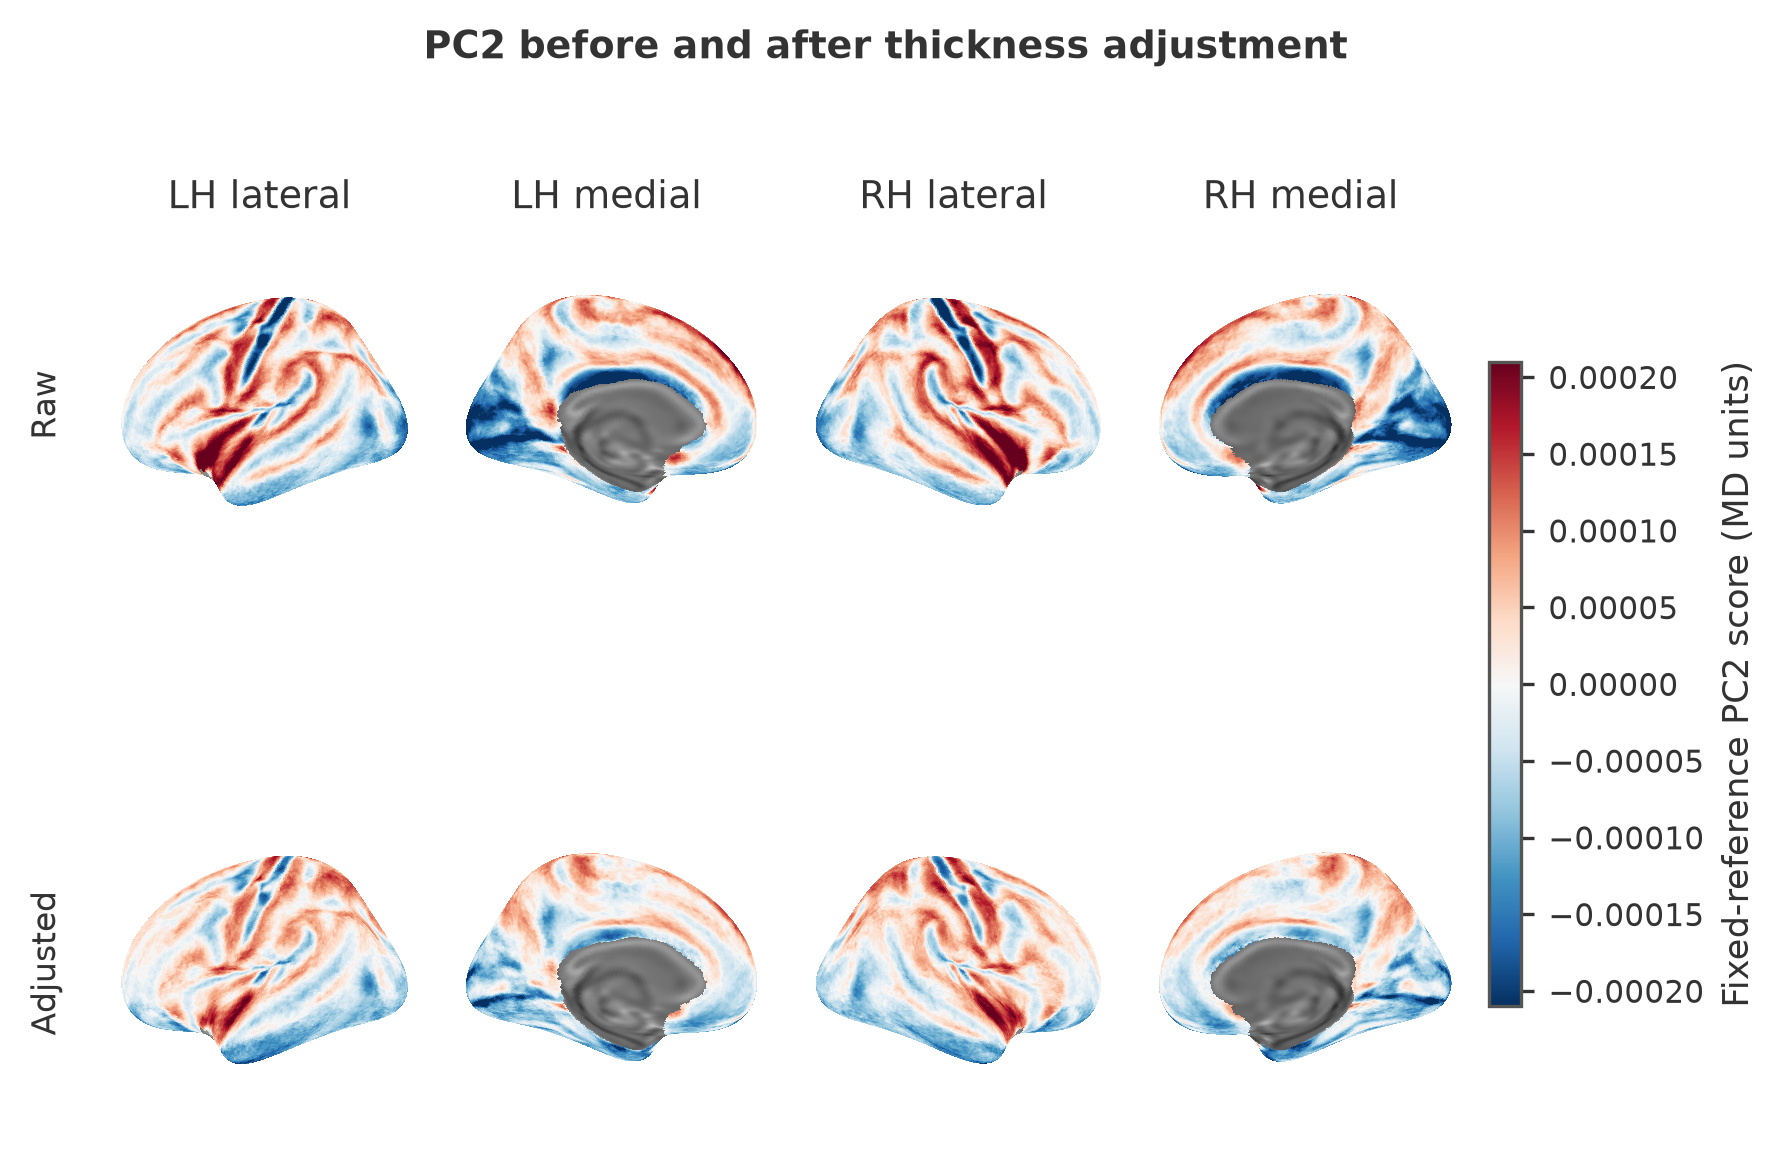

**Map caption.** Within each PC, raw and adjusted maps share one fixed zero-centered symmetric range across conditions, hemispheres and views. PC1 and PC2 use different numeric ranges; their color intensities must not be used to compare absolute score amplitudes.

### Subject-level pattern and amplitude retention

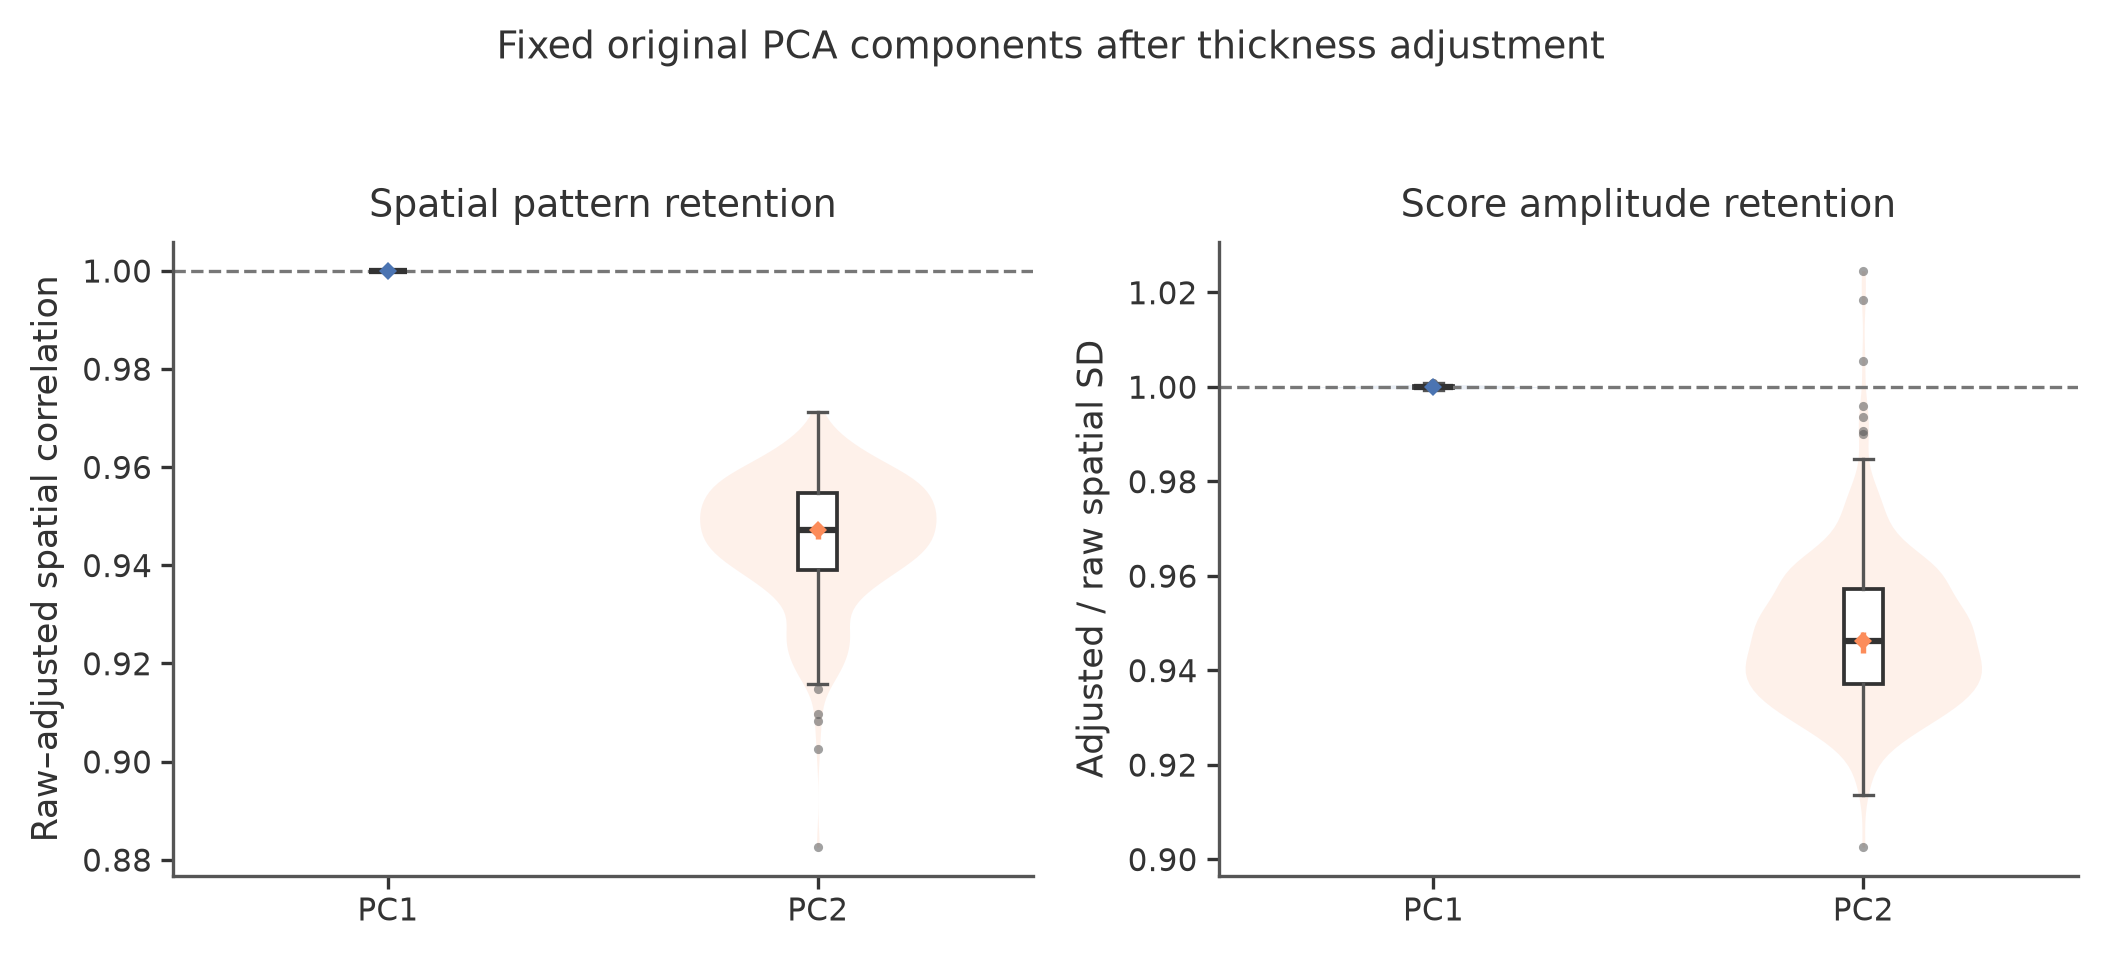

,component,metric,median,ci95_lower,ci95_upper
0,PC1,spatial_correlation_raw_adjusted,0.999992,0.999992,0.999992
1,PC1,adjusted_to_raw_sd_ratio,1.000001,0.999966,1.000030
2,PC2,spatial_correlation_raw_adjusted,0.947223,0.945382,0.948468
3,PC2,adjusted_to_raw_sd_ratio,0.946288,0.943679,0.948161


,component,group_map_spatial_correlation,adjusted_to_raw_group_map_sd_ratio
0,PC1,0.999983,0.998920
1,PC2,0.875884,0.770777


PC1 is essentially unchanged. For PC2, median subject-level pattern retention is **0.947** (95% CI **[0.945, 0.948]**) and median amplitude retention is **0.946** (95% CI **[0.944, 0.948]**). The group-mean PC2 map correlation is **0.876** with adjusted/raw spatial SD **0.771**.

In [7]:
panel_d_manifest = json.loads((QC / 'figure3D_two_selection_sets_manifest.json').read_text())
assert panel_d_manifest['status'] == 'complete' and panel_d_manifest['n_subjects'] == N
assert panel_d_manifest['interval'].startswith('Two-sided 95% t confidence interval')
assert panel_d_manifest['common_palette'] == ['blue', 'orange', 'red']
for title, stem in [
    ('P10/P50/P90 after thickness adjustment', 'Figure3D_01_quantile_adjusted_profiles'),
    ('Minimum/median/maximum after thickness adjustment', 'Figure3D_02_extreme_adjusted_profiles'),
]:
    display(Markdown(f'### {title}'))
    display(Image(filename=str(FIGURES / f'{stem}.png'), width=760))

display(Markdown('### Fixed-component cortical maps'))
display(Image(filename=str(FIGURES / 'Figure3D_03_PC1_raw_adjusted_maps.png'), width=900))
display(Image(filename=str(FIGURES / 'Figure3D_04_PC2_raw_adjusted_maps.png'), width=900))
display(Markdown(
    '**Map caption.** Within each PC, raw and adjusted maps share one fixed '
    'zero-centered symmetric range across conditions, hemispheres and views. '
    'PC1 and PC2 use different numeric ranges; their color intensities must '
    'not be used to compare absolute score amplitudes.'
))
display(Markdown('### Subject-level pattern and amplitude retention'))
display(Image(filename=str(FIGURES / 'Figure3D_05_fixed_component_retention.png'), width=900))

retention = pd.read_csv(TABLES / 'figure3D_fixed_component_retention_summary.csv')
group_retention = pd.read_csv(TABLES / 'figure3D_fixed_component_group_map_retention.csv')
assert retention.n_subjects.eq(N).all()
display(retention[['component', 'metric', 'median', 'ci95_lower', 'ci95_upper']])
display(group_retention[['component', 'group_map_spatial_correlation',
                         'adjusted_to_raw_group_map_sd_ratio']])

def retained(component, metric):
    return retention.loc[(retention.component == component) &
                         (retention.metric == metric)].iloc[0]
pc2_r = retained('PC2', 'spatial_correlation_raw_adjusted')
pc2_sd = retained('PC2', 'adjusted_to_raw_sd_ratio')
pc2_group = group_retention.loc[group_retention.component.eq('PC2')].iloc[0]
display(Markdown(
    f'PC1 is essentially unchanged. For PC2, median subject-level pattern retention is '
    f'**{pc2_r["median"]:.3f}** (95% CI **[{pc2_r.ci95_lower:.3f}, {pc2_r.ci95_upper:.3f}]**) '
    f'and median amplitude retention is **{pc2_sd["median"]:.3f}** '
    f'(95% CI **[{pc2_sd.ci95_lower:.3f}, {pc2_sd.ci95_upper:.3f}]**). '
    f'The group-mean PC2 map correlation is **{pc2_group.group_map_spatial_correlation:.3f}** '
    f'with adjusted/raw spatial SD **{pc2_group.adjusted_to_raw_group_map_sd_ratio:.3f}**.'
))

## Supplementary results

The signed depth-specific thickness coefficient is shown separately from partial $R^2$. Regional partial $R^2$ quantifies residual differences among DK regions and is not used as the shape-retention metric in D. PC1 split-half stability remains a PCA robustness check.

### Signed depth-specific thickness coefficient

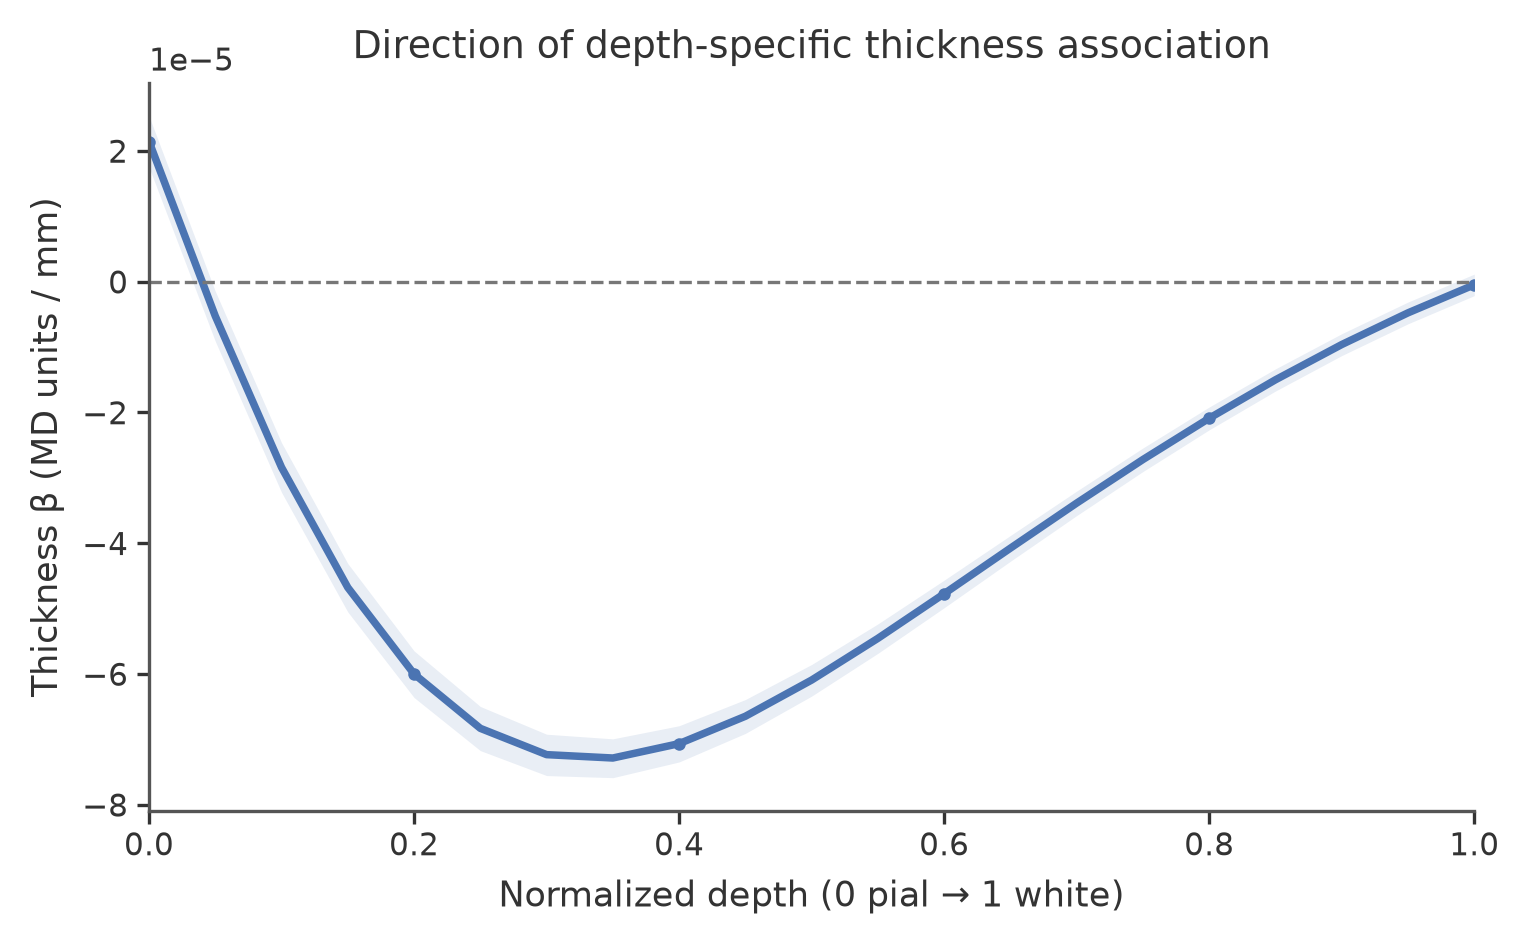

,depth_index,normalized_depth,beta_thickness,beta_ci95_lower,beta_ci95_upper
0,0,0.00,2.143450e-05,0.000018,0.000025
5,5,0.25,-6.831559e-05,-0.000072,-0.000065
10,10,0.50,-6.093250e-05,-0.000063,-0.000059
15,15,0.75,-2.720413e-05,-0.000029,-0.000025
20,20,1.00,-4.825821e-07,-0.000002,0.000001


### Regional partial R² before and after adjustment

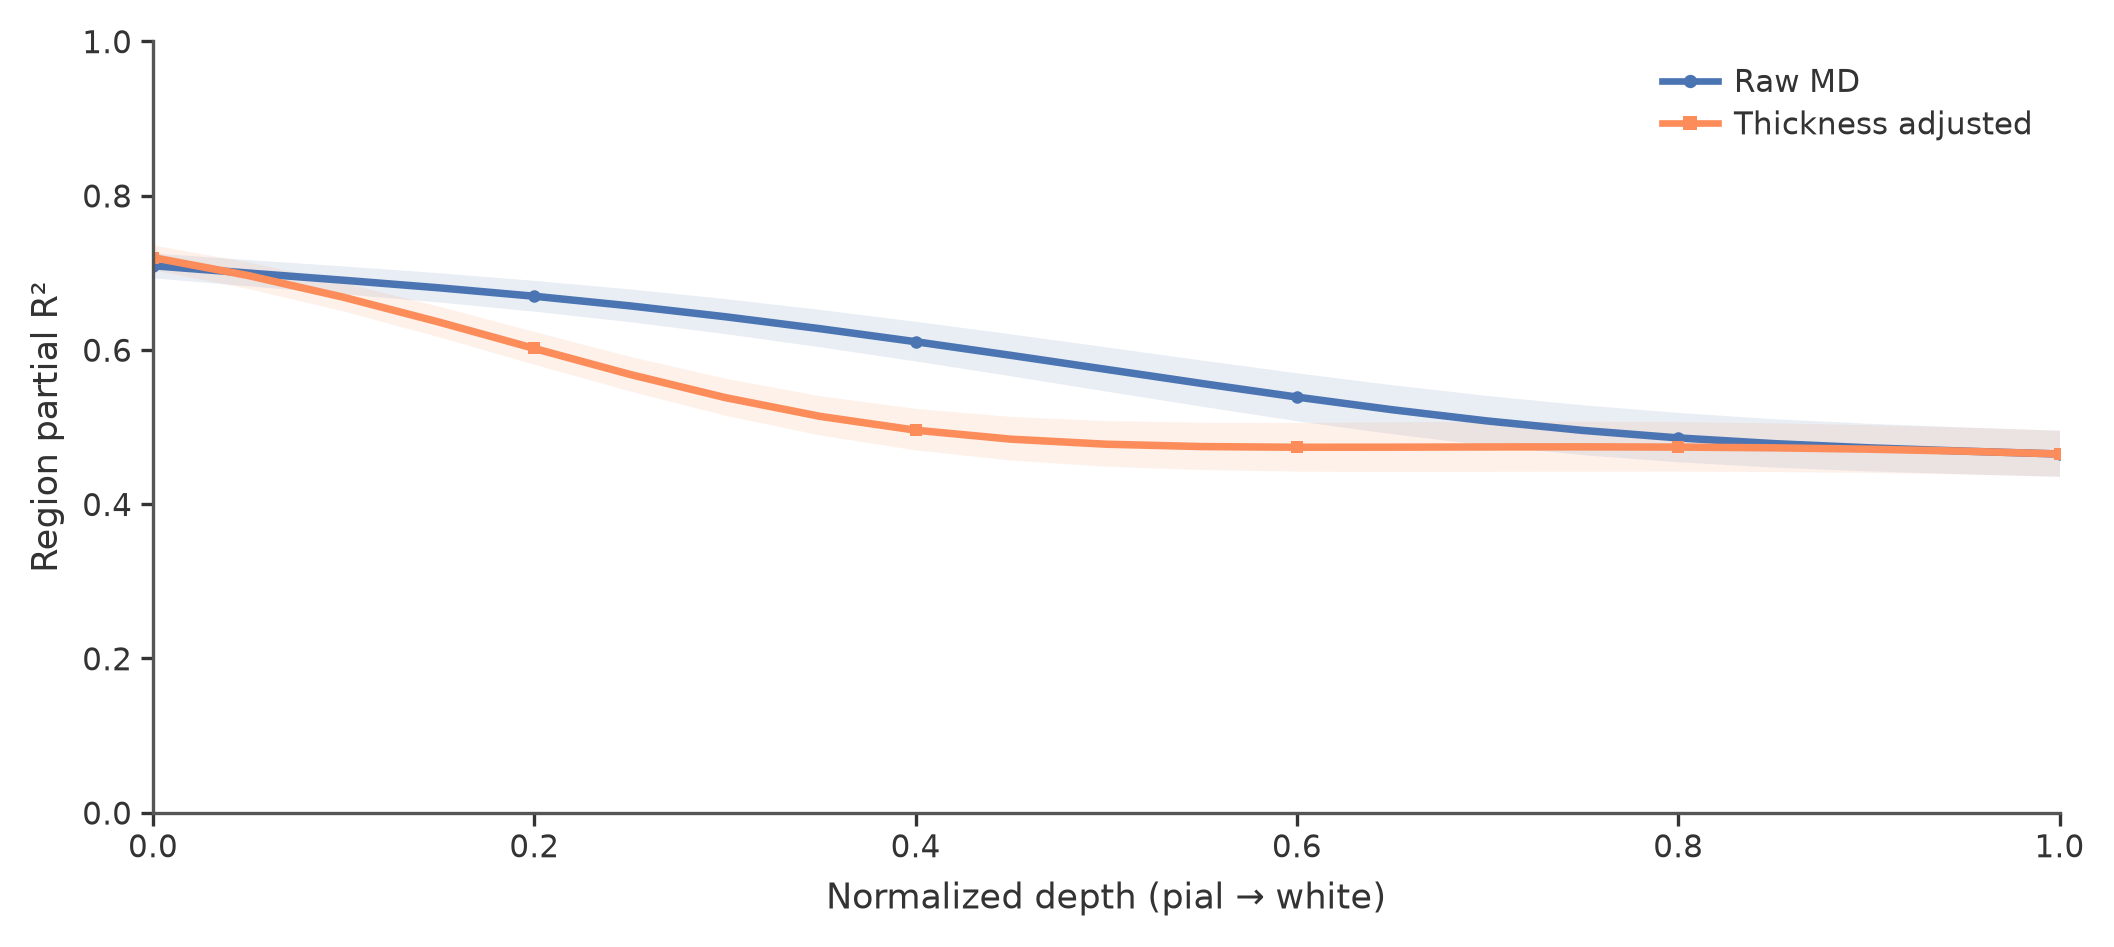

,depth_index,normalized_depth,raw_partial_r2,raw_ci95_lower,raw_ci95_upper,adjusted_partial_r2,adjusted_ci95_lower,adjusted_ci95_upper,n_subjects,n_observed_subject_region_cells
0,0,0.00,0.709131,0.693460,0.725660,0.719711,0.704026,0.736058,313,21284
5,5,0.25,0.657152,0.636576,0.679113,0.568331,0.546828,0.591755,313,21284
10,10,0.50,0.574780,0.546591,0.603919,0.477752,0.449234,0.508332,313,21284
15,15,0.75,0.495624,0.464257,0.528824,0.474359,0.442815,0.507587,313,21284
20,20,1.00,0.465052,0.436119,0.495860,0.465105,0.436215,0.495865,313,21284


### PC1 split-half stability

,loading_correlation,group_surface_map_correlation
count,100.000000,100.000000
mean,0.999965,0.966528
std,0.000060,0.001371
min,0.999585,0.962254
2.5%,0.999848,0.963453
50%,0.999989,0.966613
97.5%,0.999999,0.968738
max,1.000000,0.968935


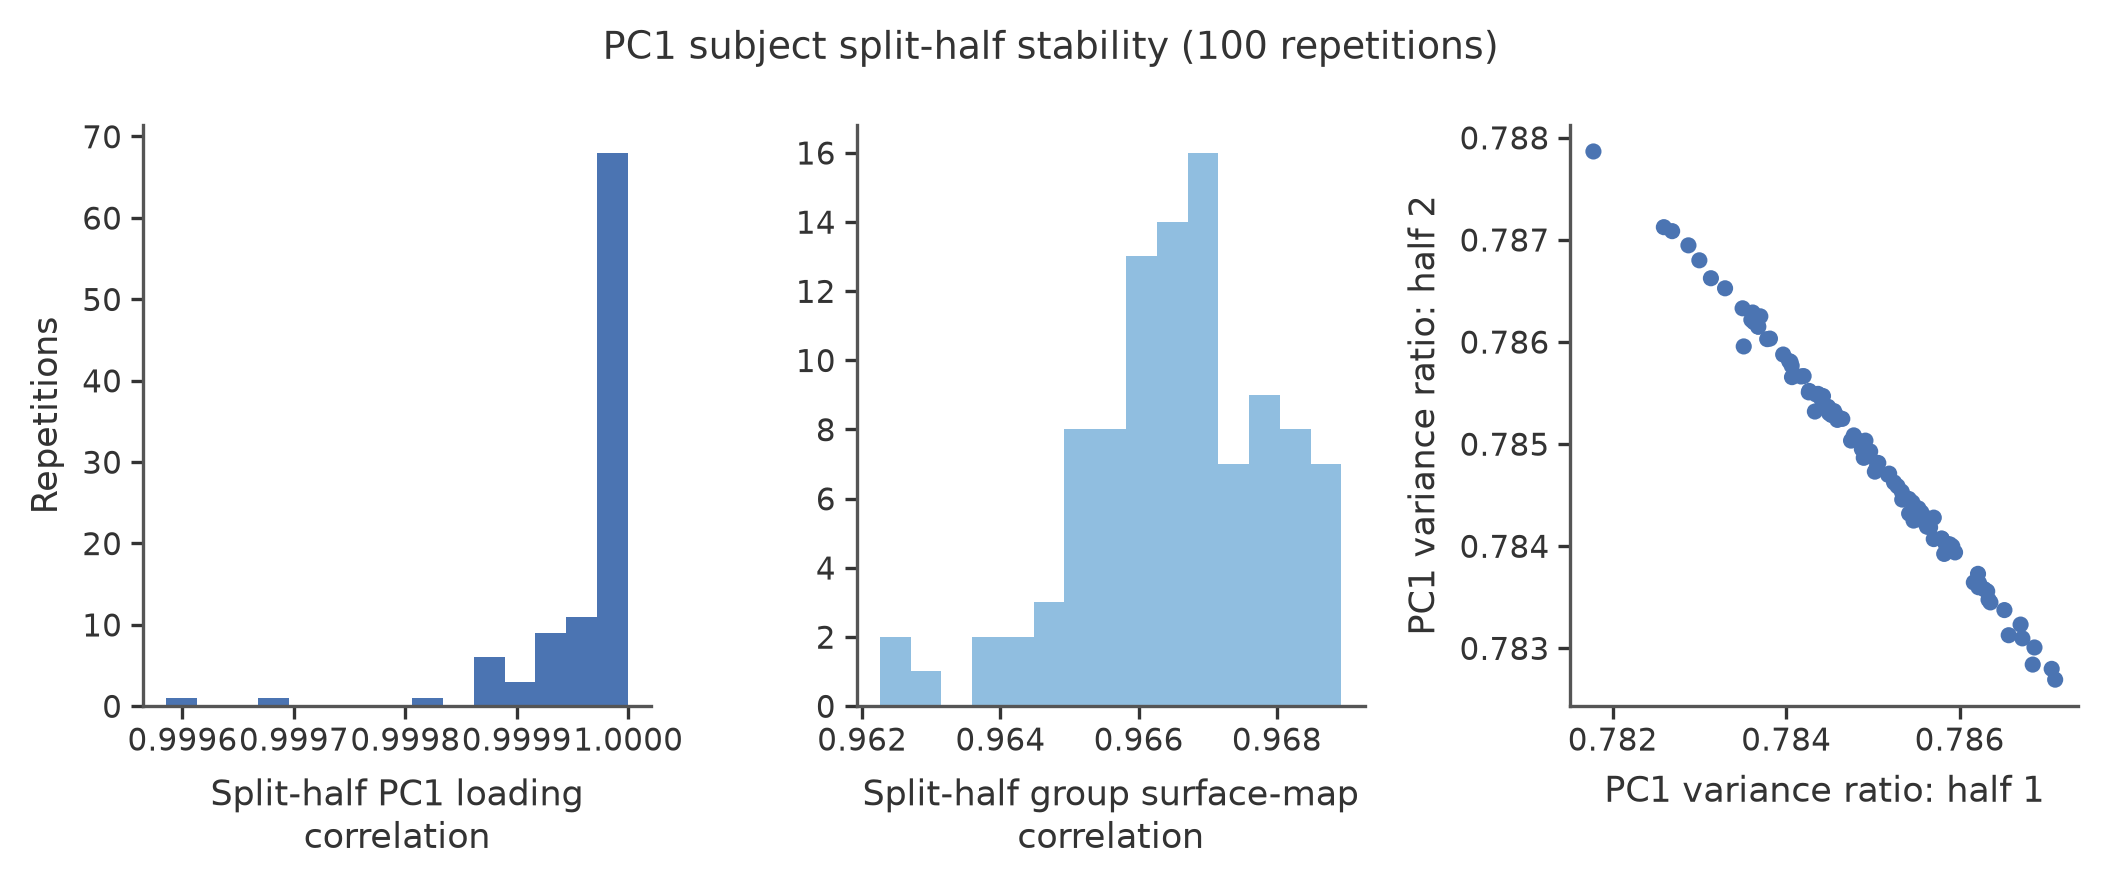

In [8]:
display(Markdown('### Signed depth-specific thickness coefficient'))
display(Image(filename=str(FIGURES / 'Figure3S_thickness_beta_by_depth.png'), width=760))
display(effects.loc[effects.depth_index.isin([0, 5, 10, 15, 20]),
                    ['depth_index', 'normalized_depth', 'beta_thickness',
                     'beta_ci95_lower', 'beta_ci95_upper']])

display(Markdown('### Regional partial R² before and after adjustment'))
regional = pd.read_csv(TABLES / 'figure3D_region_effect_by_depth.csv')
assert regional.n_subjects.eq(N).all()
display(Image(filename=str(FIGURES / 'Figure3D_raw_adjusted_region_effect.png'), width=760))
display(regional.loc[regional.depth_index.isin([0, 5, 10, 15, 20])])

display(Markdown('### PC1 split-half stability'))
stability = pd.read_csv(TABLES / 'figure3S_pc1_split_half_stability.csv')
assert len(stability) == 100
display(stability[['loading_correlation', 'group_surface_map_correlation']]
        .describe(percentiles=[.025, .5, .975]))
display(Image(filename=str(FIGURES / 'Figure3S_pc1_stability.png'), width=760))

## Result summary

In [9]:
v = variance.set_index('component').explained_variance_ratio
c = pc_summary.set_index('component')
pc1_r = retained('PC1', 'spatial_correlation_raw_adjusted')
pc1_sd = retained('PC1', 'adjusted_to_raw_sd_ratio')
curv = curvature_summary.set_index(['component', 'curvature_metric', 'metric'])
pc2_signed_curv = curv.loc[('PC2', 'signed', 'spatial_spearman_rho')]
pc2_signed_r2 = curv.loc[('PC2', 'signed', 'partial_r2_curvature')]
display(Markdown(
    f'PC1 and PC2 explain **{v.loc[1]:.1%}** and **{v.loc[2]:.1%}** of profile-shape covariance. '
    f'Thickness has little association with PC1 (median ρ **{c.loc["PC1", "median_rho"]:.3f}**) '
    f'but a clearer association with PC2 (median ρ **{c.loc["PC2", "median_rho"]:.3f}**). '
    f'After thickness adjustment, PC1 pattern and amplitude are effectively preserved '
    f'(median correlation **{pc1_r["median"]:.3f}**, SD ratio **{pc1_sd["median"]:.3f}**), '
    f'whereas PC2 changes modestly at the subject level and more visibly in the group-mean map. '
    'Thus thickness mainly overlaps the second profile-shape mode rather than the dominant first mode. '
    f'In the curvature supplement, signed curvature is also associated with PC2 '
    f'(median ρ **{pc2_signed_curv["median"]:.3f}**) and explains a median additional '
    f'**{pc2_signed_r2["median"]:.1%}** beyond thickness; this remains an observational '
    'folding association and is not removed from the primary analysis.'
))
print('Tables:', TABLES)
print('Surface maps:', OUTPUT / 'surface_maps')
print('Figures:', FIGURES)

PC1 and PC2 explain **78.5%** and **16.9%** of profile-shape covariance. Thickness has little association with PC1 (median ρ **0.015**) but a clearer association with PC2 (median ρ **0.360**). After thickness adjustment, PC1 pattern and amplitude are effectively preserved (median correlation **1.000**, SD ratio **1.000**), whereas PC2 changes modestly at the subject level and more visibly in the group-mean map. Thus thickness mainly overlaps the second profile-shape mode rather than the dominant first mode. In the curvature supplement, signed curvature is also associated with PC2 (median ρ **-0.304**) and explains a median additional **2.5%** beyond thickness; this remains an observational folding association and is not removed from the primary analysis.

Tables: /mnt/newStor/paros/paros_WORK/xintong/results/figure3_depth_thickness_coverage95/tables
Surface maps: /mnt/newStor/paros/paros_WORK/xintong/results/figure3_depth_thickness_coverage95/surface_maps
Figures: /mnt/newStor/paros/paros_WORK/xintong/results/figure3_depth_thickness_coverage95/figures
